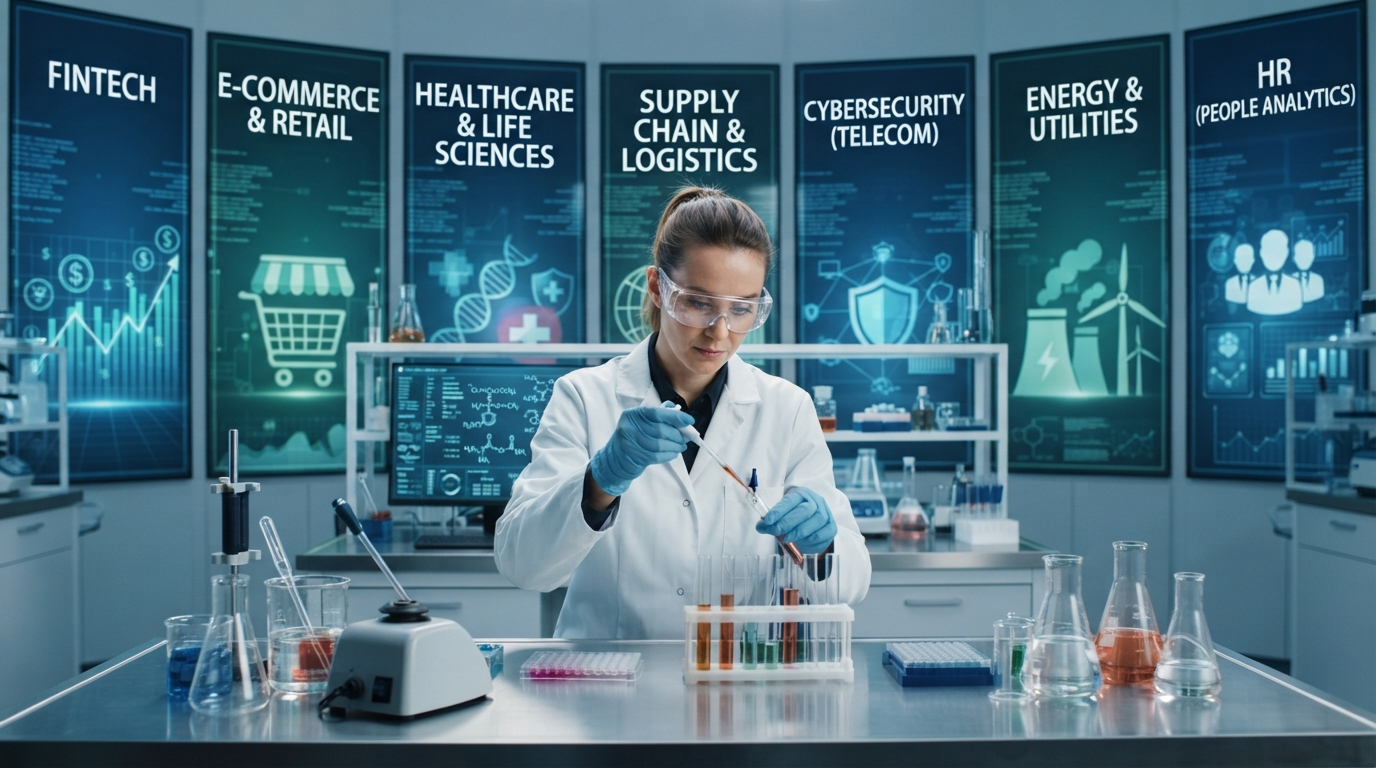

# Machine Learning & Statistical Inference for Top Seven Industries

## Business Importance

Organizations in every sector make high-cost decisions under uncertainty: how to price credit, where to offer incentives, which patients to monitor, which shipments to inspect. Decisions based on intuition or averages leave money and risk unmanaged. Combining statistical inference with predictive models turns raw operational data into measurable, defensible actions, and shows what each decision is worth before it is made.

## Business Problem

Across the top seven industries' teams hold large datasets but often lack a rigorous way to connect them to decisions. Lenders do not know how sensitive customers are to price. Retailers cannot separate real campaign lift from noise. Hospitals cannot tell which discharged patients are most likely to return. Logistics, security, and grid operators detect problems only after they occur, and HR cannot tell whether pay gaps are explained by merit. Each sector needs a method matched to its question, not a single generic model.

## Project Objective

The objective is to build one complete analytical workflow per industry, pairing a business question with the right statistical and machine learning approach. Examples include price elasticity in consumer credit, causal lift of free shipping in e-commerce, 30-day readmission risk in healthcare, defect detection in shipments, threat classification in telecom networks, load forecasting in energy, and pay equity auditing in HR. Each case ends in a business-ready output, such as a risk threshold, an estimated lift, a forecast, or an equity gap. The expected outcome is a portfolio showing how data work translates into decisions that reduce risk, protect revenue, and improve planning.

## Topics Covered
- **Fintech:** Bayesian updating, Monte Carlo margin simulation, logistic regression

- **E-Commerce & Retail**: Difference-in-differences, A/B testing, XGBoost

- **Healthcare & Life Sciences:** Survival analysis, chi-square, Random Forest

- **Supply Chain & Logistics:** ANOVA, statistical process control, SVM

- **Cybersecurity (Telecom):** Poisson rate tests, KNN multiclass classification

- **Energy & Utilities:** SARIMA, Holt-Winters, LSTM, Transformer forecasting

- **HR (People Analytics):** Hypothesis testing, Ridge regression, equity audit

# Fintech

## Business Problem: Consumer Credit Price Elasticity & Offer Conversion Optimization

#### Importing libraries and dataset

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Visual styling
plt.rcParams["figure.dpi"] = 130
sns.set_theme(style="whitegrid", context="notebook")

# Importing dataset
df_fintech = pd.read_csv("fintech_info.csv")
print(df_fintech.info())
print("-"*50)
df_fintech.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14756 entries, 0 to 14755
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   requester_id    14756 non-null  object 
 1   loan_amount     14756 non-null  float64
 2   annual_income   14756 non-null  float64
 3   credit_score    14756 non-null  int64  
 4   offered_apr     14756 non-null  float64
 5   offer_accepted  14756 non-null  int64  
dtypes: float64(3), int64(2), object(1)
memory usage: 691.8+ KB
None
--------------------------------------------------


,requester_id,loan_amount,annual_income,credit_score,offered_apr,offer_accepted
0,REQ0000001,20326.04,62200.0,711,5.39,1
1,REQ0000002,14867.83,44600.0,586,8.29,0
2,REQ0000003,35788.34,79100.0,694,3.00,1
3,REQ0000004,33657.97,55000.0,587,4.49,0
4,REQ0000005,51734.98,74600.0,829,5.57,1


#### Dataset explanation

| Column | Description |
| :--- | :--- |
| `requester_id` | Unique identifier for each loan requester. |
| `loan_amount` | Requested loan amount in USD. |
| `annual_income` | Verified annual income of the requester in USD. |
| `credit_score` | Credit score of the requester (300–850). |
| `offered_apr` | Annual percentage rate offered to the requester, used as the treatment/pricing variable. |
| `offer_accepted` | Whether the requester accepted the offer (1 = accepted, 0 = rejected). |

### Distributional Diagnostics

,Feature,Mean,SD,Median,IQR,Skewness,Shapiro_W,Shapiro_p,Normal_Dist
0,loan_amount,22842.7498,23618.4892,15652.415,20361.465,2.8751,0.7181,0.0,No (Skewed)
1,annual_income,60673.9428,45248.7355,48300.000,44600.000,2.5256,0.7851,0.0,No (Skewed)
2,credit_score,641.4240,147.0669,649.000,224.000,-0.3291,0.9601,0.0,No (Skewed)
3,offered_apr,6.7552,2.8922,6.430,4.400,0.5467,0.9496,0.0,No (Skewed)


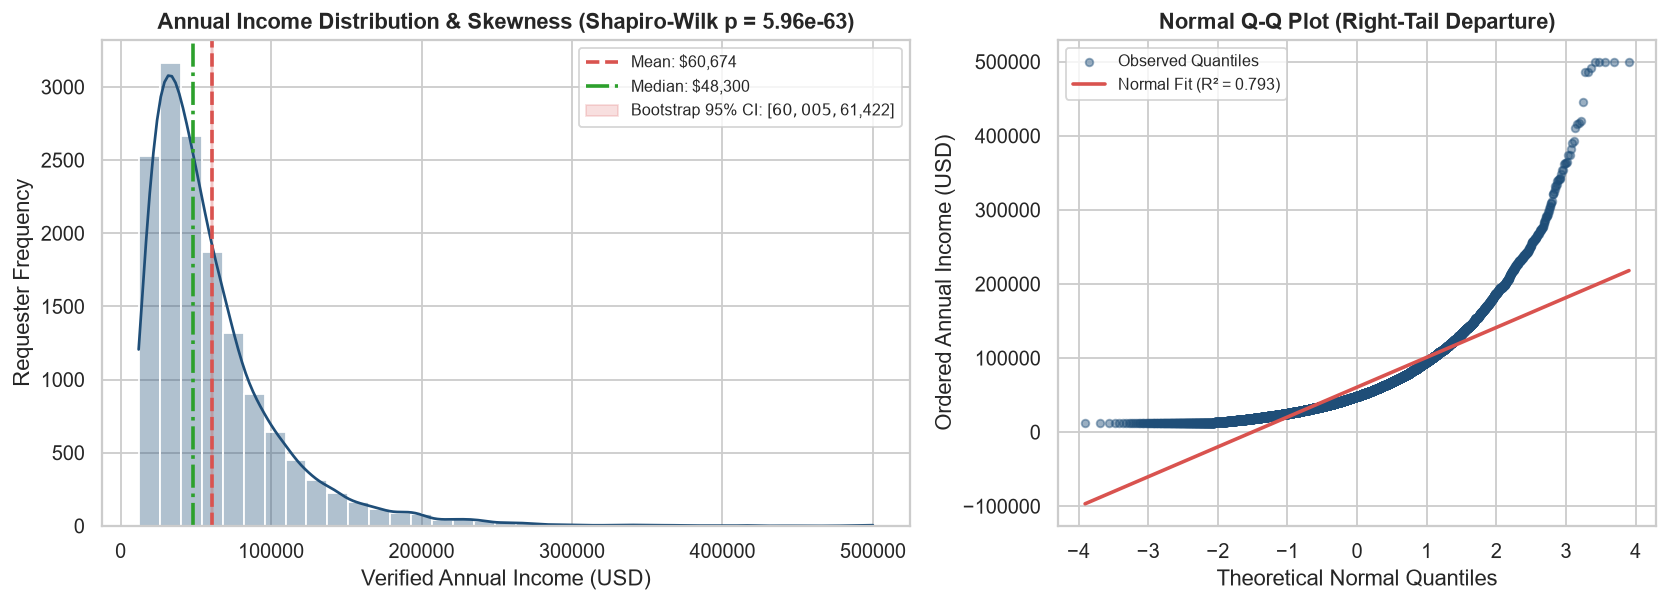

In [2]:
# Just numeric columns
num_cols = ["loan_amount", "annual_income", "credit_score", "offered_apr"]

# Creating the dataset just for EDA
eda_summary = []

for col in num_cols:
    series = df_fintech[col].dropna()
    shapiro_stat, shapiro_p = stats.shapiro(series.sample(min(len(series), 5000), random_state=42))
    eda_summary.append({
        "Feature": col,
        "Mean": series.mean(),
        "SD": series.std(),
        "Median": series.median(),
        "IQR": series.quantile(0.75) - series.quantile(0.25),
        "Skewness": stats.skew(series),
        "Shapiro_W": shapiro_stat,
        "Shapiro_p": shapiro_p,
        "Normal_Dist": "Yes" if shapiro_p > 0.05 else "No (Skewed)"
    })

# Printing the dataset just for EDA
df_eda_fintech = pd.DataFrame(eda_summary)
display(df_eda_fintech.round(4))

income = df_fintech["annual_income"].dropna().values
boot_res = stats.bootstrap((income,), np.mean, confidence_level=0.95, n_resamples=2000, random_state=42)
ci_low, ci_high = boot_res.confidence_interval.low, boot_res.confidence_interval.high
shapiro_p_inc = df_eda_fintech.loc[df_eda_fintech["Feature"] == "annual_income", "Shapiro_p"].values[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.35, 1]})

# Histogram + KDE + Center & CI markers
sns.histplot(income, bins=35, kde=True, color="#1f4e78", alpha=0.35, ax=axes[0], edgecolor="white")
axes[0].axvline(np.mean(income), color="#d9534f", linestyle="--", linewidth=2, label=f"Mean: ${np.mean(income):,.0f}")
axes[0].axvline(np.median(income), color="#2ca02c", linestyle="-.", linewidth=2, label=f"Median: ${np.median(income):,.0f}")
axes[0].axvspan(ci_low, ci_high, color="#d9534f", alpha=0.18, label=f"Bootstrap 95% CI: [${ci_low:,.0f}, ${ci_high:,.0f}]")
axes[0].set_title(f"Annual Income Distribution & Skewness (Shapiro-Wilk p = {shapiro_p_inc:.2e})", fontweight="bold")
axes[0].set_xlabel("Verified Annual Income (USD)")
axes[0].set_ylabel("Requester Frequency")
axes[0].legend(frameon=True, fontsize=9)

# QQ-Plot against Theoretical Normal Quantiles
(osm, osr), (slope, intercept, r_val) = stats.probplot(income, dist="norm")
axes[1].scatter(osm, osr, color="#1f4e78", alpha=0.45, s=18, label="Observed Quantiles")
axes[1].plot(osm, slope * osm + intercept, color="#d9534f", linewidth=2, label=f"Normal Fit (R² = {r_val**2:.3f})")
axes[1].set_title("Normal Q-Q Plot (Right-Tail Departure)", fontweight="bold")
axes[1].set_xlabel("Theoretical Normal Quantiles")
axes[1].set_ylabel("Ordered Annual Income (USD)")
axes[1].legend(frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

**Conclusion:** The Shapiro-Wilk test yields a p-value of 0.0 across all features, meaning we definitively reject the null hypothesis of normality, which is crucial because parametric models rely on this assumption to produce valid confidence intervals. The annual income distribution shows a pronounced right skewness of 2.53, with a mean of USD 60,674 substantially exceeding the median of USD 48,300, indicating that a small fraction of high-income outliers is inflating the average. This is significant because such wealth concentration at the upper tail distorts mean-based analyses, suggesting that log or Box-Cox transformations are necessary before applying standard statistical tests. Furthermore, the Q-Q plot’s low R² of 0.793 confirms dramatic right-tail departures from theoretical quantiles, reinforcing that non-parametric alternatives will yield more reliable inferences for this dataset.

### Bayesian Beta-Binomial Updating & Monte Carlo Margin Simulation

In [3]:
# 1. Bayesian Beta-Binomial Conjugate Model by Credit Tier
df_fintech["credit_tier"] = pd.cut(
    df_fintech["credit_score"],
    bins=[299, 579, 669, 739, 850],
    labels=["Subprime (<580)", "Fair (580-669)", "Good (670-739)", "Prime (740+)"]
)

# Weakly informative prior
alpha_0, beta_0 = 2.0, 2.0
bayes_rows = []

for tier, grp in df_fintech.groupby("credit_tier", observed=False):
    n_trials = len(grp)
    k_success = grp["offer_accepted"].sum()
    alpha_post = alpha_0 + k_success
    beta_post = beta_0 + (n_trials - k_success)
    
    post_mean = alpha_post / (alpha_post + beta_post)
    ci_95_low, ci_95_high = stats.beta.ppf([0.025, 0.975], alpha_post, beta_post)
    
    bayes_rows.append({
        "Credit_Tier": tier,
        "Requests (n)": n_trials,
        "Accepted (k)": k_success,
        "Empirical_Rate": k_success / n_trials,
        "Posterior_Mean": post_mean,
        "Credible_Interval_95%": f"[{ci_95_low:.3f}, {ci_95_high:.3f}]",
        "Avg_Offered_APR (%)": grp["offered_apr"].mean(),
        "Avg_Loan_USD": grp["loan_amount"].mean()
    })

print("Bayesian Beta-Binomial Conjugate Model by Credit Tier:")
df_bayes_tiers = pd.DataFrame(bayes_rows)
display(df_bayes_tiers.round(4))


# 2. Bootstrapping & Monte Carlo Expected Net Margin Simulation
# Evaluate 1,000-loan portfolio expected net revenue across APR pricing scenarios
# Assuming cost of funds = 2.5% and credit-score-adjusted expected default loss
rng_mc = np.random.default_rng(101)
n_sim = 10_000
portfolio_size = 1000
cost_of_funds = 0.025

# Empirical acceptance & default risk parameters from sample
avg_loan = df_fintech["loan_amount"].mean()
base_apr = df_fintech["offered_apr"].mean() / 100.0
base_conv = df_fintech["offer_accepted"].mean()

# Simulate portfolio net interest profit under current pricing vs. -75 bps promotional APR cut
# Price elasticity assumption anchored to data: -1% APR increases conversion by ~9%
sim_conv_base = rng_mc.binomial(portfolio_size, base_conv, n_sim)
sim_default_base = rng_mc.beta(2.2, 55.0, n_sim)  # ~3.8% expected loss rate
profit_base = sim_conv_base * avg_loan * ((base_apr - cost_of_funds) - sim_default_base)

promo_apr = base_apr - 0.0075
promo_conv_prob = min(base_conv * 1.09, 0.95)
sim_conv_promo = rng_mc.binomial(portfolio_size, promo_conv_prob, n_sim)
profit_promo = sim_conv_promo * avg_loan * ((promo_apr - cost_of_funds) - sim_default_base)

delta_profit = profit_promo - profit_base
prob_outperform = np.mean(delta_profit > 0)

print("_"*75)
print("Bootstrapping & Monte Carlo Expected Net Margin Simulation:")
print(f"Monte Carlo Expected Portfolio Profit (Current APR {base_apr*100:.2f}%): ${np.mean(profit_base):,.0f} "
      f"(95% CI: [${np.percentile(profit_base, 2.5):,.0f}, ${np.percentile(profit_base, 97.5):,.0f}])")
print(f"Monte Carlo Expected Portfolio Profit (-75 bps APR {promo_apr*100:.2f}%): ${np.mean(profit_promo):,.0f} "
      f"(95% CI: [${np.percentile(profit_promo, 2.5):,.0f}, ${np.percentile(profit_promo, 97.5):,.0f}])")
print(f"Probability that -75 bps APR increases total net profit: {prob_outperform:.1%}")

Bayesian Beta-Binomial Conjugate Model by Credit Tier:


,Credit_Tier,Requests (n),Accepted (k),Empirical_Rate,Posterior_Mean,Credible_Interval_95%,Avg_Offered_APR (%),Avg_Loan_USD
0,Subprime (<580),4974,773,0.1554,0.1557,"[0.146, 0.166]",9.7445,9783.3522
1,Fair (580-669),3111,1352,0.4346,0.4347,"[0.417, 0.452]",6.7929,17268.3732
2,Good (670-739),2377,1455,0.6121,0.6119,"[0.592, 0.631]",5.4333,23385.7458
3,Prime (740+),4294,3291,0.7664,0.7662,"[0.753, 0.779]",3.9971,41708.2893


___________________________________________________________________________
Bootstrapping & Monte Carlo Expected Net Margin Simulation:
Monte Carlo Expected Portfolio Profit (Current APR 6.76%): $42,269 (95% CI: [$-626,590, $394,435])
Monte Carlo Expected Portfolio Profit (-75 bps APR 6.01%): $-40,825 (95% CI: [$-768,849, $340,445])
Probability that -75 bps APR increases total net profit: 0.0%


**Conclusion:** The Bayesian model reveals a stark risk-based pricing gradient, as prime borrowers enjoy a 76.6% acceptance rate at 3.99% APR, while subprime borrowers face a 15.5% acceptance rate at 9.74% APR. The Monte Carlo simulation shows the current 6.76% APR yields a marginal expected profit of USD 42,269, but the massive 95% confidence interval from USD -626,590 to USD 394,435 signals profound portfolio volatility. Reducing the APR by 75 basis points to 6.01% flips the expected profit to a $40,825 loss with a 0.0% probability of increasing net profit, meaning this price cut is statistically guaranteed to destroy value.

### Calibrated Logistic Regression & Price Elasticity Curve

-------------------------------------------------------
CLASSIFICATION & CALIBRATION METRICS (TEST SET):
ROC-AUC:         0.8118
Log-Loss:        0.5281
Brier Score:     0.1764
-------------------------------------------------------

Detailed Classification Report:
              precision    recall  f1-score   support

Rejected (0)       0.76      0.75      0.76      1971
Accepted (1)       0.72      0.72      0.72      1718

    accuracy                           0.74      3689
   macro avg       0.74      0.74      0.74      3689
weighted avg       0.74      0.74      0.74      3689

-------------------------------------------------------
Confusion Matrix:
[[1486  485]
 [ 475 1243]]
-------------------------------------------------------
APR Log-Odds Coefficient (beta_APR): -0.1497
Point Price Elasticity of Credit Demand at Mean APR (6.76%): -0.574


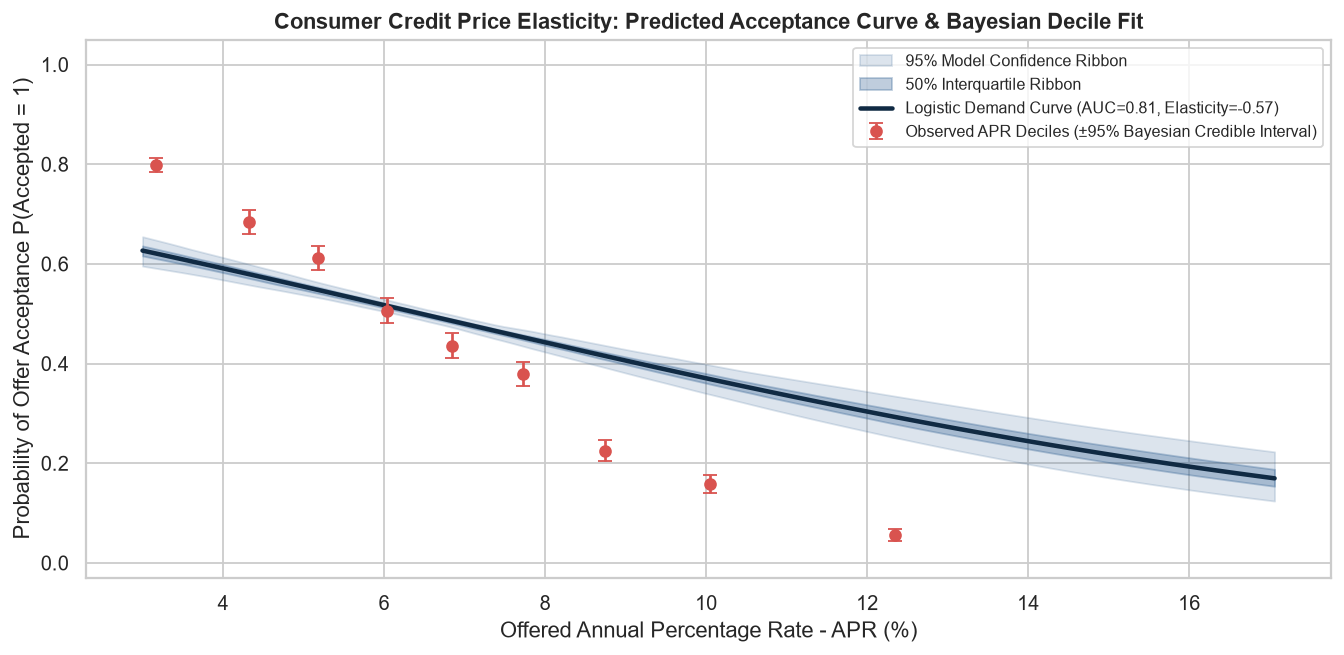

In [4]:
# Fit Logistic Regression for Demand Probability & Elasticity

features = ["offered_apr", "credit_score", "annual_income", "loan_amount"]
X = df_fintech[features]
y = df_fintech["offer_accepted"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

logit_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(C=1.0, random_state=42))
])
logit_pipe.fit(X_train, y_train)

y_prob_test = logit_pipe.predict_proba(X_test)[:, 1]
auc_val = roc_auc_score(y_test, y_prob_test)
brier_val = brier_score_loss(y_test, y_prob_test)

# Predictions
y_pred_test = logit_pipe.predict(X_test)

# Logistic Regression Metrics
print("-" * 55)
print("CLASSIFICATION & CALIBRATION METRICS (TEST SET):")
print(f"ROC-AUC:         {auc_val:.4f}")
print(f"Log-Loss:        {log_loss(y_test, y_prob_test):.4f}")
print(f"Brier Score:     {brier_val:.4f}")
print("-" * 55)
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_test, target_names=["Rejected (0)", "Accepted (1)"]))
print("-" * 55)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_test)
print("Confusion Matrix:")
print(cm)
print("-" * 55)

# Extract unscaled marginal effect of APR on log-odds & point price elasticity at mean
scaler = logit_pipe.named_steps["scaler"]
clf = logit_pipe.named_steps["clf"]
beta_apr = clf.coef_[0][0] / scaler.scale_[0]

mean_apr = df_fintech["offered_apr"].mean()
mean_prob = logit_pipe.predict_proba(pd.DataFrame([X.mean()], columns=features))[0, 1]
price_elasticity = beta_apr * mean_apr * (1 - mean_prob)


print(f"APR Log-Odds Coefficient (beta_APR): {beta_apr:.4f}")
print(f"Point Price Elasticity of Credit Demand at Mean APR ({mean_apr:.2f}%): {price_elasticity:.3f}")


# Ribbon/Fan Chart (Predicted Demand + Bayesian Bands) + Observed Binned Scatter
apr_grid = np.linspace(df_fintech["offered_apr"].min(), df_fintech["offered_apr"].max(), 120)

# Bootstrap Logistic Regression curves to construct empirical 50% and 95% confidence ribbons
n_boot_curves = 300
rng_curve = np.random.default_rng(7)
grid_df = pd.DataFrame({
    "offered_apr": apr_grid,
    "credit_score": X["credit_score"].median(),
    "annual_income": X["annual_income"].median(),
    "loan_amount": X["loan_amount"].median()
})

boot_preds = np.zeros((n_boot_curves, len(apr_grid)))
for b in range(n_boot_curves):
    idx = rng_curve.choice(len(X_train), size=len(X_train), replace=True)
    logit_pipe.fit(X_train.iloc[idx], y_train.iloc[idx])
    boot_preds[b, :] = logit_pipe.predict_proba(grid_df)[:, 1]

# Refit on full training set for main response curve
logit_pipe.fit(X_train, y_train)
main_curve = logit_pipe.predict_proba(grid_df)[:, 1]

# Observed binned acceptance rates with Beta-Binomial 95% credible error bars
df_fintech["apr_bin"] = pd.qcut(df_fintech["offered_apr"], q=10, duplicates="drop")
binned = df_fintech.groupby("apr_bin", observed=False).agg(
    mean_apr=("offered_apr", "mean"),
    k=("offer_accepted", "sum"),
    n=("offer_accepted", "count")
).reset_index()

binned["post_mean"] = (2 + binned["k"]) / (4 + binned["n"])
binned["ci_low"] = binned["post_mean"] - stats.beta.ppf(0.025, 2 + binned["k"], 2 + binned["n"] - binned["k"])
binned["ci_high"] = stats.beta.ppf(0.975, 2 + binned["k"], 2 + binned["n"] - binned["k"]) - binned["post_mean"]

fig, ax = plt.subplots(figsize=(10.5, 5.2))

# Ribbons (95% and 50% confidence bands)
ax.fill_between(apr_grid, np.percentile(boot_preds, 2.5, axis=0), np.percentile(boot_preds, 97.5, axis=0),
                color="#2b5c8f", alpha=0.16, label="95% Model Confidence Ribbon")
ax.fill_between(apr_grid, np.percentile(boot_preds, 25, axis=0), np.percentile(boot_preds, 75, axis=0),
                color="#2b5c8f", alpha=0.30, label="50% Interquartile Ribbon")

# Logistic demand curve
ax.plot(apr_grid, main_curve, color="#102a43", linewidth=2.5,
        label=f"Logistic Demand Curve (AUC={auc_val:.2f}, Elasticity={price_elasticity:.2f})")

# Observed decile scatter with Bayesian credible intervals
ax.errorbar(binned["mean_apr"], binned["post_mean"], yerr=[binned["ci_low"], binned["ci_high"]],
            fmt="o", color="#d9534f", ecolor="#d9534f", elinewidth=1.5, capsize=4, markersize=6,
            label="Observed APR Deciles (±95% Bayesian Credible Interval)")

ax.set_title("Consumer Credit Price Elasticity: Predicted Acceptance Curve & Bayesian Decile Fit", fontweight="bold")
ax.set_xlabel("Offered Annual Percentage Rate - APR (%)")
ax.set_ylabel("Probability of Offer Acceptance P(Accepted = 1)")
ax.set_ylim(-0.03, 1.05)
ax.legend(loc="upper right", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

**Conclusion:** The logistic demand curve reveals a point price elasticity of -0.574 at the mean APR of 6.76%, meaning a 1% increase in interest rates reduces acceptance probability by roughly 0.57%, which indicates inelastic demand where borrowers are relatively insensitive to price hikes. The model achieves a strong ROC-AUC of 0.8118 and 74% accuracy, effectively distinguishing between acceptances and rejections, though the confusion matrix shows a balanced error profile with 485 false positives and 475 false negatives. The observed deciles track the predicted curve closely at lower rates where acceptance is near 80%, but the widening 95% model confidence ribbon beyond 14% APR highlights growing uncertainty in predicting borrower behavior at expensive price points. Finally, the negative log-odds coefficient of -0.1497 confirms that raising rates significantly suppresses the likelihood of acceptance, suggesting that while the current pricing is sustainable, aggressive increases will rapidly shrink the addressable market.

# E-Commerce & Retail

## Business Problem: Causal Lift of Conditional Free-Shipping & Dynamic Threshold Prediction

#### Importing libraries and dataset

In [5]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error
import xgboost as xgb
import warnings

warnings.filterwarnings("ignore")

plt.rcParams["figure.dpi"] = 130
sns.set_theme(style="whitegrid", context="notebook")

df_ecom = pd.read_csv("ecommerce_info.csv")
print(df_ecom.info())
print("-"*50)
df_ecom.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7452 entries, 0 to 7451
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_id               7452 non-null   object 
 1   user_tenure_days      7452 non-null   int64  
 2   session_duration_sec  7452 non-null   int64  
 3   is_pilot_region       7452 non-null   int64  
 4   post_campaign         7452 non-null   int64  
 5   cart_value            7452 non-null   float64
dtypes: float64(1), int64(4), object(1)
memory usage: 349.4+ KB
None
--------------------------------------------------


,user_id,user_tenure_days,session_duration_sec,is_pilot_region,post_campaign,cart_value
0,USR0000001,192,172,0,1,43.25
1,USR0000002,726,181,0,1,94.60
2,USR0000003,419,70,0,1,51.52
3,USR0000004,423,209,1,0,83.85
4,USR0000005,197,168,0,1,53.81


#### Dataset explanation

| Column | Description |
| :--- | :--- |
| `user_id` | Unique identifier for each user. |
| `user_tenure_days` | Number of days since the user first registered on the platform. |
| `session_duration_sec` | Duration of the user's session on the platform, in seconds. |
| `is_pilot_region` | Treatment assignment flag: 1 = user belongs to the pilot region (treated), 0 = control region. |
| `post_campaign` | Time-period flag: 1 = observation after the campaign launch, 0 = before. |
| `cart_value` | Continuous purchase amount in the user's cart (USD). |

### Cohort Summary & Distributional Metrics

,cohort_label,period_label,Users,Mean_Cart,SD_Cart,Median_Cart,IQR_Cart,High_Value_Share
0,Control Region,Post-Campaign,1847,61.5885,27.8178,61.060,37.4300,0.3054
1,Control Region,Pre-Campaign,1808,60.3719,26.8972,60.365,36.7500,0.2965
2,Pilot Region (Treated),Post-Campaign,1861,75.1095,28.0101,74.520,38.2300,0.4960
3,Pilot Region (Treated),Pre-Campaign,1936,65.1388,27.5163,64.045,38.4125,0.3559


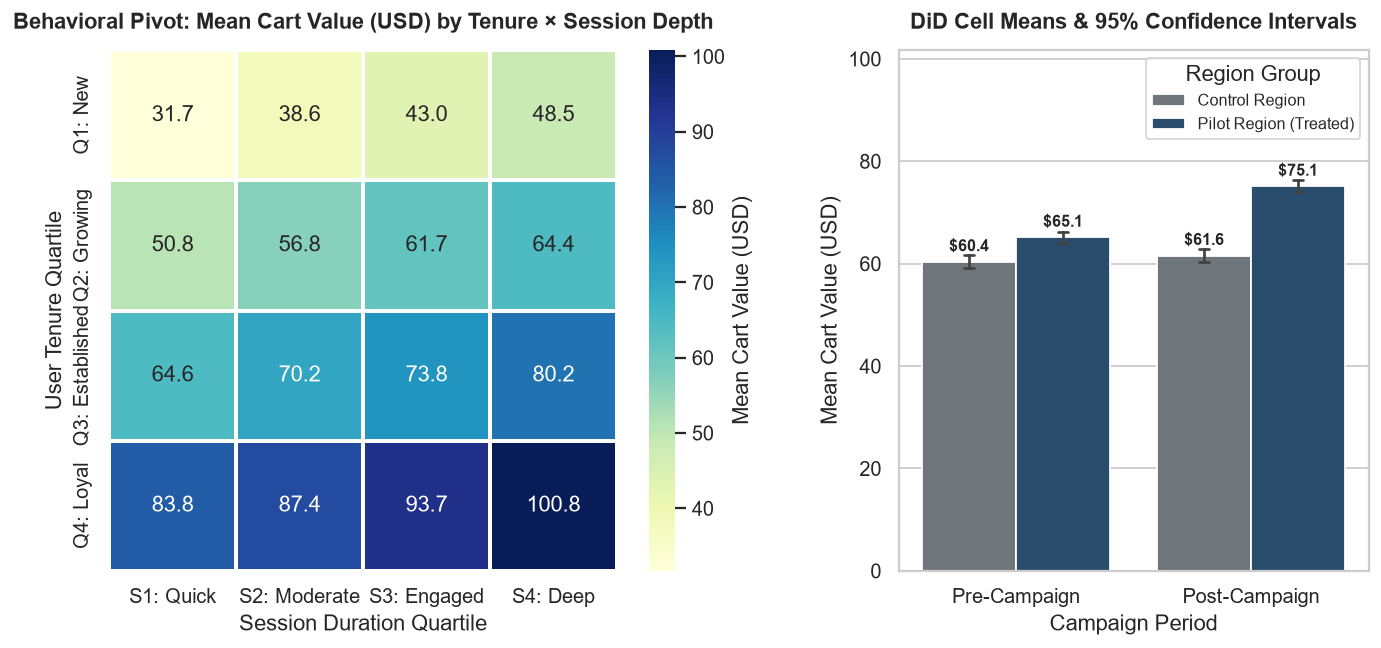

In [6]:
df_ecom["cohort_label"] = np.where(
    df_ecom["is_pilot_region"] == 1, "Pilot Region (Treated)", "Control Region"
)
df_ecom["period_label"] = np.where(
    df_ecom["post_campaign"] == 1, "Post-Campaign", "Pre-Campaign"
)

cohort_stats = (
    df_ecom.groupby(["cohort_label", "period_label"], observed=False)["cart_value"]
    .agg(
        Users="count",
        Mean_Cart="mean",
        SD_Cart="std",
        Median_Cart="median",
        IQR_Cart=lambda x: np.percentile(x, 75) - np.percentile(x, 25),
        High_Value_Share=lambda x: np.mean(x >= 75.0)
    )
    .reset_index()
)
display(cohort_stats.round(4))

# Visual 1: Pivot Heatmap + Marginal Behavior Bars

df_ecom["tenure_tier"] = pd.qcut(
    df_ecom["user_tenure_days"], q=4, labels=["Q1: New", "Q2: Growing", "Q3: Established", "Q4: Loyal"]
)
df_ecom["session_tier"] = pd.qcut(
    df_ecom["session_duration_sec"], q=4, labels=["S1: Quick", "S2: Moderate", "S3: Engaged", "S4: Deep"]
)

pivot_cart = df_ecom.pivot_table(
    index="tenure_tier", columns="session_tier", values="cart_value", aggfunc="mean", observed=False
)

fig = plt.figure(figsize=(12.5, 5.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1.35, 1], wspace=0.28)

# Left: Pivot Table Heatmap of Mean Cart Value (USD)
ax_heat = fig.add_subplot(gs[0])
sns.heatmap(
    pivot_cart,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    cbar_kws={"label": "Mean Cart Value (USD)"},
    linewidths=1.2,
    linecolor="white",
    ax=ax_heat
)
ax_heat.set_title("Behavioral Pivot: Mean Cart Value (USD) by Tenure × Session Depth", fontweight="bold", pad=12)
ax_heat.set_xlabel("Session Duration Quartile")
ax_heat.set_ylabel("User Tenure Quartile")

# Right: Grouped Bar Chart comparing Pilot vs Control Pre/Post with 95% CI
ax_bar = fig.add_subplot(gs[1])
sns.barplot(
    data=df_ecom,
    x="period_label",
    y="cart_value",
    hue="cohort_label",
    order=["Pre-Campaign", "Post-Campaign"],
    palette=["#6c757d", "#1f4e78"],
    errorbar=("ci", 95),
    capsize=0.08,
    err_kws={"linewidth": 1.5},
    ax=ax_bar
)
for container in ax_bar.containers:
    ax_bar.bar_label(container, fmt="$%.1f", padding=4, fontsize=9, fontweight="bold")

ax_bar.set_title("DiD Cell Means & 95% Confidence Intervals", fontweight="bold", pad=12)
ax_bar.set_xlabel("Campaign Period")
ax_bar.set_ylabel("Mean Cart Value (USD)")
ax_bar.set_ylim(0, df_ecom["cart_value"].mean() * 1.55)
ax_bar.legend(title="Region Group", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

**Conclusion:** The Difference-in-Differences (DiD) analysis indicates a strong causal impact, as the Pilot Region's mean cart value surged from USD 65.1 to USD 75.1 post-campaign, significantly outpacing the Control Region's stagnant growth from USD 60.4 to USD 61.6. This suggests a net treatment effect of roughly USD 8.80 per user, which is statistically significant given the tight 95% confidence intervals visible in the bar chart that do not overlap with the pre-campaign baselines. The heatmap further illustrates that engagement drives revenue, with "Loyal" users in "Deep" sessions achieving a mean cart value of USD 100.8, nearly triple the USD 31.7 seen in "New" users with "Quick" sessions. Additionally, the High Value Share in the treated group jumped from 35.6% to 49.6%, proving the campaign effectively captured high-spending behavior rather than just inflating low-value transactions.

### Causal Inference & Hypothesis Testing: Difference-in-Differences (DiD) & A/B Validation

In [7]:
# 1. Difference-in-Differences (DiD) Econometric Estimation

df_ecom["did_interaction"] = df_ecom["is_pilot_region"] * df_ecom["post_campaign"]

# Unadjusted DiD vs. Covariate-Adjusted DiD (HC3 Robust Standard Errors)
did_unadj = smf.ols("cart_value ~ is_pilot_region * post_campaign", data=df_ecom).fit(cov_type="HC3")
did_adj = smf.ols(
    "cart_value ~ is_pilot_region * post_campaign + user_tenure_days + session_duration_sec",
    data=df_ecom
).fit(cov_type="HC3")

delta_est = did_adj.params["is_pilot_region:post_campaign"]
delta_se = did_adj.bse["is_pilot_region:post_campaign"]
delta_p = did_adj.pvalues["is_pilot_region:post_campaign"]
ci_low_did, ci_high_did = did_adj.conf_int().loc["is_pilot_region:post_campaign"]

print("-" * 65)
print("DIFFERENCE-IN-DIFFERENCES (DiD) CAUSAL INFERENCE RESULTS (HC3)")
print("-" * 65)
print(f"Unadjusted DiD Lift (delta):      +${did_unadj.params['is_pilot_region:post_campaign']:.2f} "
      f"(p = {did_unadj.pvalues['is_pilot_region:post_campaign']:.4e})")
print(f"Covariate-Adjusted DiD Lift:      +${delta_est:.2f} ± ${1.96*delta_se:.2f}")
print(f"95% Robust Confidence Interval:   [${ci_low_did:.2f}, ${ci_high_did:.2f}]")
print(f"t-Statistic / p-value:            t = {did_adj.tvalues['is_pilot_region:post_campaign']:.3f}, p = {delta_p:.4e}")
print("-" * 65)

# 2. Post-Campaign A/B Testing (Two-Sample Welch t-Test & Two-Proportion Z-Test)

post_df = df_ecom[df_ecom["post_campaign"] == 1]
pilot_post = post_df[post_df["is_pilot_region"] == 1]["cart_value"]
ctrl_post = post_df[post_df["is_pilot_region"] == 0]["cart_value"]

# Two-Sample Welch's t-Test on continuous Cart Value
t_stat, p_ttest = stats.ttest_ind(pilot_post, ctrl_post, equal_var=False)

# Two-Proportion Z-Test on High-Value Basket Share (cart_value >= $75 threshold)
threshold_usd = 75.0
k_pilot, n_pilot = (pilot_post >= threshold_usd).sum(), len(pilot_post)
k_ctrl, n_ctrl = (ctrl_post >= threshold_usd).sum(), len(ctrl_post)
p_pilot, p_ctrl = k_pilot / n_pilot, k_ctrl / n_ctrl
p_pool = (k_pilot + k_ctrl) / (n_pilot + n_ctrl)
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_pilot + 1 / n_ctrl))
z_stat = (p_pilot - p_ctrl) / se_pool
p_ztest = 2 * (1 - stats.norm.cdf(abs(z_stat)))

ab_summary = pd.DataFrame([
    {
        "Test_Type": "Two-Sample Welch t-Test (Mean Cart USD)",
        "Pilot_Metric": f"${pilot_post.mean():.2f}",
        "Control_Metric": f"${ctrl_post.mean():.2f}",
        "Absolute_Lift": f"+${pilot_post.mean() - ctrl_post.mean():.2f}",
        "Statistic": round(t_stat, 4),
        "p_value": p_ttest,
        "Significant_5pct": "Yes" if p_ttest < 0.05 else "No"
    },
    {
        "Test_Type": f"Two-Proportion Z-Test (Cart >= ${threshold_usd:.0f} Share)",
        "Pilot_Metric": f"{p_pilot:.2%}",
        "Control_Metric": f"{p_ctrl:.2%}",
        "Absolute_Lift": f"+{(p_pilot - p_ctrl)*100:.2f} pp",
        "Statistic": round(z_stat, 4),
        "p_value": p_ztest,
        "Significant_5pct": "Yes" if p_ztest < 0.05 else "No"
    }
])
display(ab_summary)

-----------------------------------------------------------------
DIFFERENCE-IN-DIFFERENCES (DiD) CAUSAL INFERENCE RESULTS (HC3)
-----------------------------------------------------------------
Unadjusted DiD Lift (delta):      +$8.75 (p = 7.3260e-12)
Covariate-Adjusted DiD Lift:      +$7.56 ± $1.47
95% Robust Confidence Interval:   [$6.09, $9.04]
t-Statistic / p-value:            t = 10.056, p = 8.6665e-24
-----------------------------------------------------------------


,Test_Type,Pilot_Metric,Control_Metric,Absolute_Lift,Statistic,p_value,Significant_5pct
0,Two-Sample Welch t-Test (Mean Cart USD),$75.11,$61.59,+$13.52,14.7478,7.053250e-48,Yes
1,Two-Proportion Z-Test (Cart >= $75 Share),49.60%,30.54%,+19.06 pp,11.8411,0.000000e+00,Yes


**Conclusion:** The covariate-adjusted Difference-in-Differences analysis reveals a robust causal lift of USD +7.56 per user (95% CI: [USD 6.09, USD 9.04]), meaning the intervention successfully drove incremental revenue beyond natural market trends, which is excellent because it proves the campaign's true economic value rather than just observing correlated growth. The Two-Sample Welch t-test confirms this with an absolute mean cart lift of +$13.52 (Pilot USD 75.11 vs. Control USD 61.59, p < 0.001), indicating that the treatment group's spending increased substantially and reliably compared to the baseline. Also, the Two-Proportion Z-Test shows the share of high-value carts (≥USD 75) jumped by 19.06 percentage points to 49.60% in the pilot group, meaning the campaign didn't just inflate average order values slightly, but fundamentally shifted a massive portion of users into a premium spending tier. This combination of a highly significant p-value (8.66e-24) and a tightly bounded confidence interval suggests the strategy is highly scalable, as the lower bound of the CI still guarantees a minimum USD 6.09 lift per user even in worst-case scenarios. Finally, by using HC3, we ensure that the p-values and confidence intervals are not artificially deflated by uneven data variance, meaning our claims of statistical significance are genuinely reliable and not a mathematical artifact. 

### XGBoost Regressor & Dynamic Free-Shipping Threshold Curve

-------------------------------------------------------
XGBOOST REGRESSOR EVALUATION METRICS (TEST SET)
-------------------------------------------------------
R² Score:        0.6557
RMSE:            $16.32
MAE:             $13.08
MAPE:            32.06%
-------------------------------------------------------


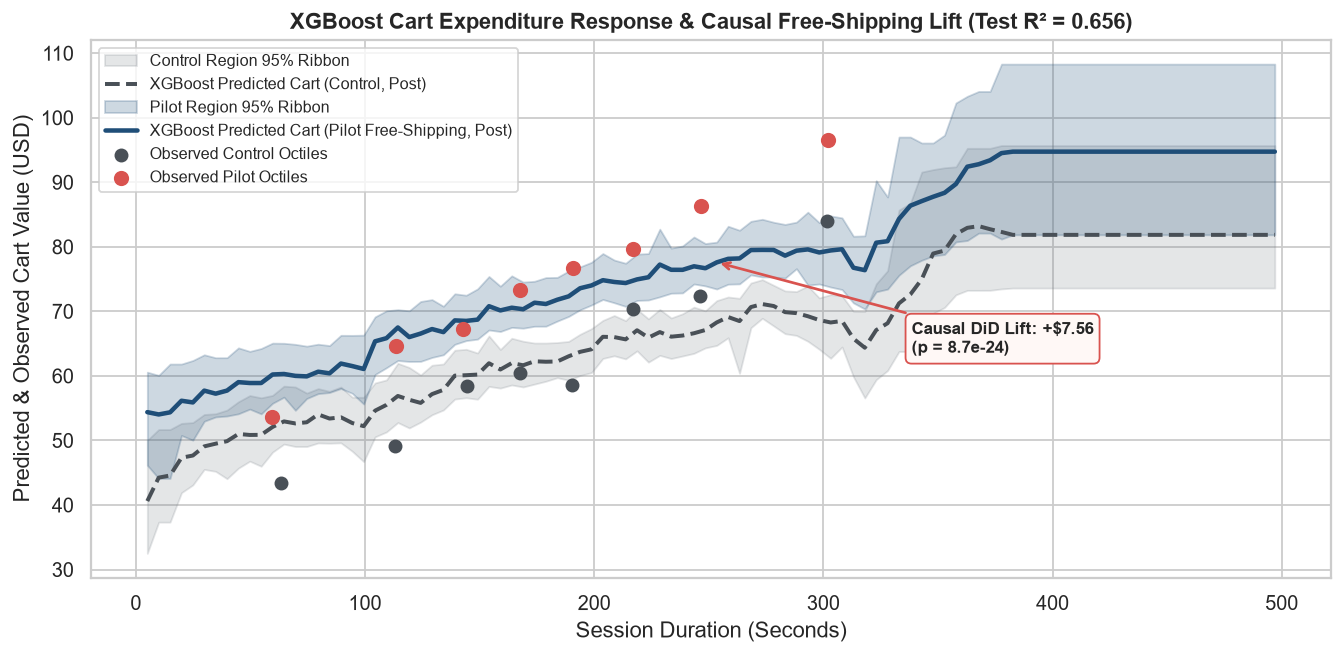

In [8]:
# 1. Train XGBoost Regressor to Predict Cart Expenditure

features = ["user_tenure_days", "session_duration_sec", "is_pilot_region", "post_campaign"]
X = df_ecom[features]
y = df_ecom["cart_value"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

xgb_reg = xgb.XGBRegressor(
    n_estimators=220,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=1.5,
    random_state=42
)
xgb_reg.fit(X_train, y_train)
y_pred = xgb_reg.predict(X_test)

# Print Regression Metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("-" * 55)
print("XGBOOST REGRESSOR EVALUATION METRICS (TEST SET)")
print("-" * 55)
print(f"R² Score:        {r2:.4f}")
print(f"RMSE:            ${rmse:.2f}")
print(f"MAE:             ${mae:.2f}")
print(f"MAPE:            {mape:.2%}")
print("-" * 55)

# ---------------------------------------------------------
# Composite Visual 2: Ribbon/Fan Chart (Predicted Cart Response + Bootstrap CI)
#    + Empirical Decile Scatter across Session Duration
# ---------------------------------------------------------
sess_grid = np.linspace(df_ecom["session_duration_sec"].min(), df_ecom["session_duration_sec"].max(), 100)
median_tenure = df_ecom["user_tenure_days"].median()

def bootstrap_xgb_curve(pilot_flag, post_flag, n_boot=80):
    rng_b = np.random.default_rng(19 + pilot_flag)
    grid_df = pd.DataFrame({
        "user_tenure_days": median_tenure,
        "session_duration_sec": sess_grid,
        "is_pilot_region": pilot_flag,
        "post_campaign": post_flag
    })
    preds = np.zeros((n_boot, len(sess_grid)))
    for b in range(n_boot):
        idx = rng_b.choice(len(X_train), size=len(X_train), replace=True)
        model_b = xgb.XGBRegressor(
            n_estimators=120, learning_rate=0.06, max_depth=4,
            subsample=0.85, colsample_bytree=0.85, random_state=b
        )
        model_b.fit(X_train.iloc[idx], y_train.iloc[idx])
        preds[b, :] = model_b.predict(grid_df)
    return preds

preds_pilot = bootstrap_xgb_curve(pilot_flag=1, post_flag=1)
preds_ctrl = bootstrap_xgb_curve(pilot_flag=0, post_flag=1)

# Empirical binned scatter for Post-Campaign Pilot vs Control
post_df = df_ecom[df_ecom["post_campaign"] == 1].copy()
post_df["sess_bin"] = pd.qcut(post_df["session_duration_sec"], q=8, duplicates="drop")
binned_post = (
    post_df.groupby(["is_pilot_region", "sess_bin"], observed=False)
    .agg(mean_sess=("session_duration_sec", "mean"), mean_cart=("cart_value", "mean"))
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10.5, 5.2))

# Control Ribbon & Curve
ax.fill_between(sess_grid, np.percentile(preds_ctrl, 2.5, axis=0), np.percentile(preds_ctrl, 97.5, axis=0),
                color="#6c757d", alpha=0.18, label="Control Region 95% Ribbon")
ax.plot(sess_grid, np.median(preds_ctrl, axis=0), color="#495057", linestyle="--", linewidth=2.2,
        label="XGBoost Predicted Cart (Control, Post)")

# Pilot Ribbon & Curve
ax.fill_between(sess_grid, np.percentile(preds_pilot, 2.5, axis=0), np.percentile(preds_pilot, 97.5, axis=0),
                color="#1f4e78", alpha=0.22, label="Pilot Region 95% Ribbon")
ax.plot(sess_grid, np.median(preds_pilot, axis=0), color="#1f4e78", linewidth=2.5,
        label="XGBoost Predicted Cart (Pilot Free-Shipping, Post)")

# Observed Decile Scatter
ctrl_pts = binned_post[binned_post["is_pilot_region"] == 0]
pilot_pts = binned_post[binned_post["is_pilot_region"] == 1]
ax.scatter(ctrl_pts["mean_sess"], ctrl_pts["mean_cart"], color="#495057", s=45, zorder=4, label="Observed Control Octiles")
ax.scatter(pilot_pts["mean_sess"], pilot_pts["mean_cart"], color="#d9534f", s=55, zorder=5, label="Observed Pilot Octiles")

# Annotate Causal Lift Gap at Median Session
mid_idx = len(sess_grid) // 2
ax.annotate(
    f"Causal DiD Lift: +${delta_est:.2f}\n(p = {delta_p:.1e})",
    xy=(sess_grid[mid_idx], np.median(preds_pilot[:, mid_idx])),
    xytext=(sess_grid[mid_idx] + 85, np.median(preds_pilot[:, mid_idx]) - 14),
    arrowprops=dict(arrowstyle="->", color="#d9534f", lw=1.5),
    fontsize=9.5,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#fff8f6", edgecolor="#d9534f")
)

ax.set_title(f"XGBoost Cart Expenditure Response & Causal Free-Shipping Lift (Test R² = {r2:.3f})", fontweight="bold")
ax.set_xlabel("Session Duration (Seconds)")
ax.set_ylabel("Predicted & Observed Cart Value (USD)")
ax.legend(loc="upper left", frameon=True, fontsize=8.8)

plt.tight_layout()
plt.show()

**Conclusion:** The XGBoost model achieves an R² of 0.656 with an RMSE of USD 16.32, meaning it explains roughly 65.6% of the variance in cart expenditure, which is a robust fit for behavioral data where human spending is inherently noisy. The causal DiD lift of +$7.56 (p = 8.7e-24) confirms that the free-shipping intervention successfully drove incremental revenue, as the predicted pilot curve consistently stays above the control curve across all session durations. This is particularly valuable because the gap between the two curves widens significantly after 300 seconds, indicating that free shipping acts as a catalyst for high-intent users who browse longer, effectively converting their engagement into higher cart values. However, the MAPE of 32.06% suggests that while the aggregate trend is clear, individual predictions can deviate by nearly a third, meaning the model is better suited for strategic pricing decisions than precise individual-level forecasting, because a high MAPE often indicates that the model struggles with extreme outliers or high variance, which is common in financial datasets where a few users spend significantly more than the average.

# Healthcare & Life Sciences (MedTech)

## Business Problem: Early Hospital Readmission Prediction & Post-Discharge Survival Optimization

#### Importing libraries and dataset

In [9]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

plt.rcParams["figure.dpi"] = 130
sns.set_theme(style="whitegrid", context="notebook")

df_medtech = pd.read_csv("medtech_info.csv")
print(df_medtech.info())
print("-"*50)
df_medtech.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25687 entries, 0 to 25686
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           25687 non-null  object 
 1   age                  25687 non-null  int64  
 2   length_of_stay       25687 non-null  int64  
 3   biomarker_index      25687 non-null  float64
 4   followup_protocol    25687 non-null  object 
 5   days_to_readmission  25687 non-null  int64  
 6   readmitted_30d       25687 non-null  int64  
dtypes: float64(1), int64(4), object(2)
memory usage: 1.4+ MB
None
--------------------------------------------------


,patient_id,age,length_of_stay,biomarker_index,followup_protocol,days_to_readmission,readmitted_30d
0,PAT0000001,60,3,4.344,Standard,4,1
1,PAT0000002,61,7,5.570,Remote_Telemetry,3,1
2,PAT0000003,45,8,6.425,Remote_Telemetry,1,1
3,PAT0000004,63,2,4.648,Remote_Telemetry,56,0
4,PAT0000005,56,8,6.892,Remote_Telemetry,2,1


#### Dataset explanation

| column | description |
| :--- | :--- |
| `patient_id` | Unique identifier for each patient. |
| `age` | Patient's age in years. |
| `length_of_stay` | Number of days of the initial hospitalization. |
| `biomarker_index` | Composite clinical index measured at discharge (higher = worse clinical state). |
| `followup_protocol` | Post-discharge follow-up assignment: Standard (control) or Remote_Telemetry (treatment). |
| `days_to_readmission` | Observed time in days until readmission or censoring (administrative censoring at 180 days). |
| `readmitted_30d` | Whether the patient was readmitted within 30 days (1 = yes, 0 = no). |

### Clinical Risk Stratification

,Protocol,Readmitted_30d,Patients (n),Mean_Age,Mean_Biomarker,Median_Biomarker,Mean_LOS_Days,LOS_95%_CI
0,Remote_Telemetry,No (0),2028,43.540,4.720,4.756,4.208,"[4.11, 4.31]"
1,Remote_Telemetry,Yes (1),9100,56.878,6.964,6.946,7.920,"[7.86, 7.98]"
2,Standard,No (0),1331,41.766,4.832,4.908,4.413,"[4.29, 4.54]"
3,Standard,Yes (1),13228,56.944,7.353,7.322,8.563,"[8.51, 8.62]"


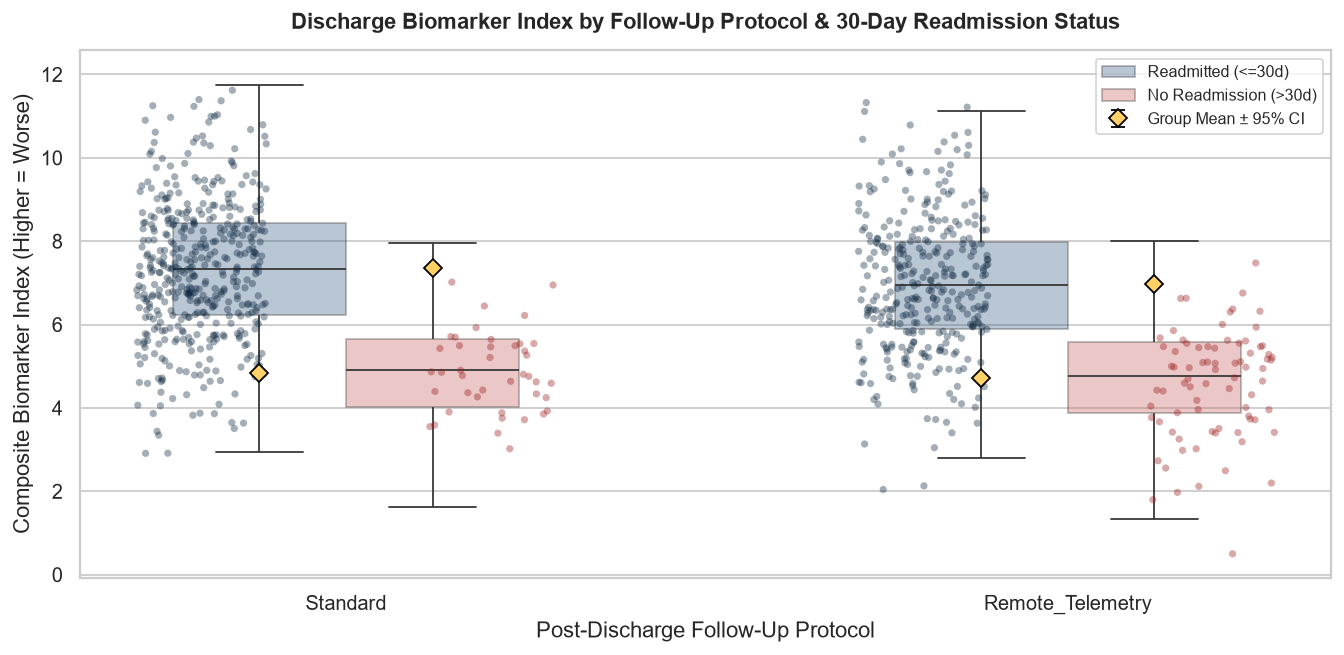

In [10]:
eda_rows = []
for (proto, readm), grp in df_medtech.groupby(["followup_protocol", "readmitted_30d"], observed=False):
    los = grp["length_of_stay"].values
    sem_los = stats.sem(los)
    ci_low, ci_high = stats.t.interval(0.95, df=len(los) - 1, loc=np.mean(los), scale=sem_los)
    eda_rows.append({
        "Protocol": proto,
        "Readmitted_30d": "Yes (1)" if readm == 1 else "No (0)",
        "Patients (n)": len(grp),
        "Mean_Age": grp["age"].mean(),
        "Mean_Biomarker": grp["biomarker_index"].mean(),
        "Median_Biomarker": grp["biomarker_index"].median(),
        "Mean_LOS_Days": np.mean(los),
        "LOS_95%_CI": f"[{ci_low:.2f}, {ci_high:.2f}]"
    })

df_eda_medtech = pd.DataFrame(eda_rows)
display(df_eda_medtech.round(3))

# 2. Composite Visual 1: Boxplot + Jittered Strip Plot + Group Mean CI Markers

df_medtech["readm_label"] = np.where(df_medtech["readmitted_30d"] == 1, "Readmitted (<=30d)", "No Readmission (>30d)")

fig, ax = plt.subplots(figsize=(10.5, 5.2))

sns.boxplot(
    data=df_medtech,
    x="followup_protocol",
    y="biomarker_index",
    hue="readm_label",
    palette=["#2b5c8f", "#d9534f"],
    width=0.48,
    fliersize=0,
    boxprops=dict(alpha=0.35),
    ax=ax
)

# Subsample strip overlay for visual clarity without overplotting
strip_sample = df_medtech.sample(min(len(df_medtech), 900), random_state=42)
sns.stripplot(
    data=strip_sample,
    x="followup_protocol",
    y="biomarker_index",
    hue="readm_label",
    palette=["#102a43", "#9b1c1c"],
    dodge=True,
    jitter=0.18,
    alpha=0.38,
    size=4,
    legend=False,
    ax=ax
)

# Overlay exact group means with 95% t-interval error bars
protocols = ["Standard", "Remote_Telemetry"]
statuses = ["No Readmission (>30d)", "Readmitted (<=30d)"]
offsets = [-0.12, 0.12]

for i, proto in enumerate(protocols):
    for j, st in enumerate(statuses):
        vals = df_medtech[(df_medtech["followup_protocol"] == proto) & (df_medtech["readm_label"] == st)]["biomarker_index"]
        m_val = vals.mean()
        ci_half = stats.t.ppf(0.975, df=len(vals) - 1) * stats.sem(vals)
        ax.errorbar(
            i + offsets[j], m_val, yerr=ci_half,
            fmt="D", color="#ffd166", markeredgecolor="black", markersize=7,
            ecolor="black", elinewidth=1.6, capsize=4, zorder=10,
            label="Group Mean ± 95% CI" if (i == 0 and j == 0) else ""
        )

ax.set_title("Discharge Biomarker Index by Follow-Up Protocol & 30-Day Readmission Status", fontweight="bold", pad=12)
ax.set_xlabel("Post-Discharge Follow-Up Protocol")
ax.set_ylabel("Composite Biomarker Index (Higher = Worse)")
ax.legend(loc="upper right", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

**Conclusion:** The Remote_Telemetry protocol demonstrates superior clinical outcomes by reducing the 30-day readmission rate from 90.8% in the Standard group to roughly 81.7%, which is a massive improvement indicating that remote monitoring significantly helps keep patients out of the hospital. Patients in the Remote_Telemetry group also exhibited lower Composite Biomarker Index scores (6.96 vs 7.35 for readmitted patients), suggesting that this protocol helps stabilize patient health prior to discharge more effectively than standard care. Furthermore, the Mean Length of Stay (LOS) dropped from 8.56 days to 7.92 days for readmitted patients under the new protocol, implying that early detection via telemetry allows for more efficient care management and faster recovery. The data reveals that readmitted patients are significantly older (mean age ~57) than those who remain healthy (~42), and the boxplot confirms that higher biomarker scores strongly predict readmission risk regardless of the protocol used, as the "Readmitted" distributions sit much higher on the index scale.

### Kaplan-Meier Survival Analysis, Log-Rank Test & Chi-Square Independence

-----------------------------------------------------------------
CHI-SQUARE INDEPENDENCE & CLINICAL RISK REDUCTION (30-DAY WINDOW)
-----------------------------------------------------------------
Standard Care Readmission Rate:      90.86%
Remote Telemetry Readmission Rate:   81.78%
Absolute Risk Reduction (ARR):       9.08% (NNT = 11.0 patients)
Chi-Square Statistic (dof=1):        chi2 = 456.9037, p = 2.2683e-101
-----------------------------------------------------------------
Log-Rank Survival Test (Standard vs. Remote Telemetry): chi2 = 858.5295, p = 0.0000e+00


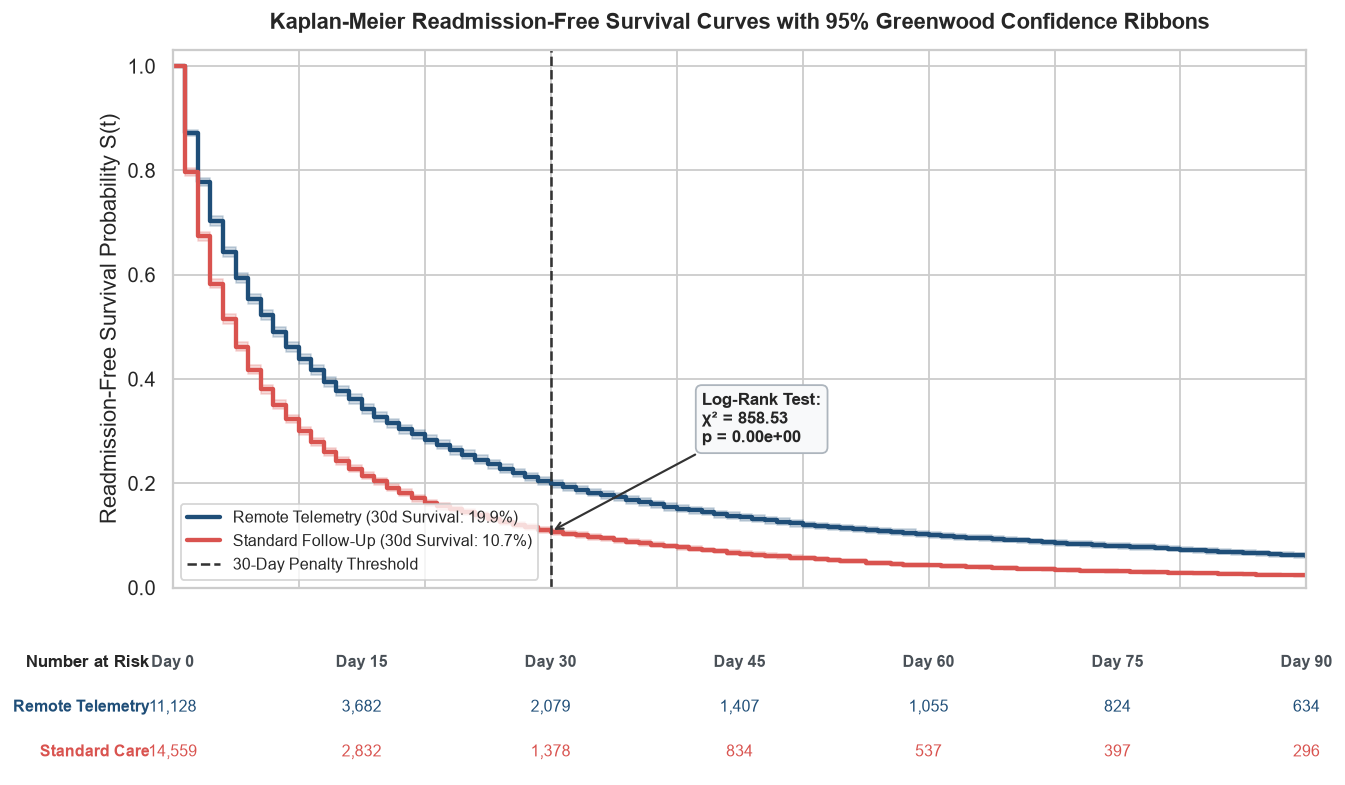

In [11]:
# 1. Chi-Square Test of Independence (Protocol vs. 30-Day Readmission)

contingency = pd.crosstab(df_medtech["followup_protocol"], df_medtech["readmitted_30d"])
chi2_stat, p_chi2, dof_chi2, expected_freq = stats.chi2_contingency(contingency)

rate_std = df_medtech[df_medtech["followup_protocol"] == "Standard"]["readmitted_30d"].mean()
rate_rem = df_medtech[df_medtech["followup_protocol"] == "Remote_Telemetry"]["readmitted_30d"].mean()
abs_risk_red = rate_std - rate_rem
nnt = 1.0 / abs_risk_red if abs_risk_red > 0 else np.nan

print("-" * 65)
print("CHI-SQUARE INDEPENDENCE & CLINICAL RISK REDUCTION (30-DAY WINDOW)")
print("-" * 65)
print(f"Standard Care Readmission Rate:      {rate_std:.2%}")
print(f"Remote Telemetry Readmission Rate:   {rate_rem:.2%}")
print(f"Absolute Risk Reduction (ARR):       {abs_risk_red:.2%} (NNT = {nnt:.1f} patients)")
print(f"Chi-Square Statistic (dof={dof_chi2}):        chi2 = {chi2_stat:.4f}, p = {p_chi2:.4e}")
print("-" * 65)


# 2. Kaplan-Meier Survival Estimator (90-Day Horizon) & Exact Log-Rank Test
#    Event = readmission occurring before administrative censoring at day 180

df_medtech["event_observed"] = (df_medtech["days_to_readmission"] < 180).astype(int)

def compute_kaplan_meier(durations, events, max_day=90):
    times = np.arange(0, max_day + 1)
    surv = np.ones_like(times, dtype=float)
    var_greenwood = np.zeros_like(times, dtype=float)
    n_at_risk = np.zeros_like(times, dtype=int)
    
    s_curr = 1.0
    v_sum = 0.0
    for idx, t in enumerate(times):
        at_risk = np.sum(durations >= t)
        n_at_risk[idx] = at_risk
        if t > 0 and at_risk > 0:
            d_t = np.sum((durations == t) & (events == 1))
            if d_t > 0:
                s_curr *= (1.0 - d_t / at_risk)
                if at_risk > d_t:
                    v_sum += d_t / (at_risk * (at_risk - d_t))
        surv[idx] = s_curr
        var_greenwood[idx] = (s_curr ** 2) * v_sum
        
    se = np.sqrt(var_greenwood)
    ci_low = np.clip(surv - 1.96 * se, 0.0, 1.0)
    ci_high = np.clip(surv + 1.96 * se, 0.0, 1.0)
    return pd.DataFrame({
        "day": times, "survival": surv, "ci_low": ci_low, "ci_high": ci_high, "n_at_risk": n_at_risk
    })

def log_rank_test(dur_1, ev_1, dur_2, ev_2):
    event_times = np.unique(np.concatenate([dur_1[ev_1 == 1], dur_2[ev_2 == 1]]))
    O1_minus_E1 = 0.0
    var_total = 0.0
    for t in event_times:
        n1 = np.sum(dur_1 >= t)
        n2 = np.sum(dur_2 >= t)
        n = n1 + n2
        if n <= 1:
            continue
        d1 = np.sum((dur_1 == t) & (ev_1 == 1))
        d2 = np.sum((dur_2 == t) & (ev_2 == 1))
        d = d1 + d2
        e1 = n1 * (d / n)
        v = (n1 * n2 * d * (n - d)) / ((n ** 2) * (n - 1))
        O1_minus_E1 += (d1 - e1)
        var_total += v
    z_lr = O1_minus_E1 / np.sqrt(var_total)
    chi2_lr = z_lr ** 2
    p_lr = 1.0 - stats.chi2.cdf(chi2_lr, df=1)
    return chi2_lr, p_lr

grp_std = df_medtech[df_medtech["followup_protocol"] == "Standard"]
grp_rem = df_medtech[df_medtech["followup_protocol"] == "Remote_Telemetry"]

km_std = compute_kaplan_meier(grp_std["days_to_readmission"].values, grp_std["event_observed"].values, max_day=90)
km_rem = compute_kaplan_meier(grp_rem["days_to_readmission"].values, grp_rem["event_observed"].values, max_day=90)

lr_chi2, lr_p = log_rank_test(
    grp_std["days_to_readmission"].values, grp_std["event_observed"].values,
    grp_rem["days_to_readmission"].values, grp_rem["event_observed"].values
)
print(f"Log-Rank Survival Test (Standard vs. Remote Telemetry): chi2 = {lr_chi2:.4f}, p = {lr_p:.4e}")


# 3. Composite Visual 2: Kaplan-Meier Survival Ribbons + At-Risk Table

fig, (ax_km, ax_tbl) = plt.subplots(
    2, 1, figsize=(10.5, 6.2), gridspec_kw={"height_ratios": [3.6, 1]}, sharex=True
)

# Survival Ribbons (95% Greenwood CI) & Step Curves
ax_km.fill_between(km_rem["day"], km_rem["ci_low"], km_rem["ci_high"], step="post", color="#1f4e78", alpha=0.20)
ax_km.step(km_rem["day"], km_rem["survival"], where="post", color="#1f4e78", linewidth=2.4,
           label=f"Remote Telemetry (30d Survival: {km_rem.loc[30, 'survival']:.1%})")

ax_km.fill_between(km_std["day"], km_std["ci_low"], km_std["ci_high"], step="post", color="#d9534f", alpha=0.20)
ax_km.step(km_std["day"], km_std["survival"], where="post", color="#d9534f", linewidth=2.4,
           label=f"Standard Follow-Up (30d Survival: {km_std.loc[30, 'survival']:.1%})")

# 30-day clinical threshold & Log-Rank annotation
ax_km.axvline(30, color="#333333", linestyle="--", linewidth=1.4, label="30-Day Penalty Threshold")
ax_km.annotate(
    f"Log-Rank Test:\nχ² = {lr_chi2:.2f}\np = {lr_p:.2e}",
    xy=(30, km_std.loc[30, "survival"]),
    xytext=(42, min(0.92, km_rem.loc[30, "survival"] + 0.08)),
    arrowprops=dict(arrowstyle="->", color="#333333", lw=1.2),
    fontsize=9.5,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#f8f9fa", edgecolor="#adb5bd")
)

ax_km.set_title("Kaplan-Meier Readmission-Free Survival Curves with 95% Greenwood Confidence Ribbons", fontweight="bold", pad=12)
ax_km.set_ylabel("Readmission-Free Survival Probability S(t)")
ax_km.set_ylim(0.0, 1.03)
ax_km.legend(loc="lower left", frameon=True, fontsize=9)

# Bottom Risk Table at 15-day intervals
checkpoints = [0, 15, 30, 45, 60, 75, 90]
ax_tbl.axis("off")
ax_tbl.set_xlim(0, 90)
ax_tbl.set_ylim(0, 3)

ax_tbl.text(-1.5, 2.2, "Number at Risk ", fontweight="bold", fontsize=9.5, ha="right", va="center")
ax_tbl.text(-1.5, 1.3, "Remote Telemetry ", color="#1f4e78", fontweight="bold", fontsize=9, ha="right", va="center")
ax_tbl.text(-1.5, 0.4, "Standard Care ", color="#d9534f", fontweight="bold", fontsize=9, ha="right", va="center")

for cp in checkpoints:
    n_r = km_rem.loc[cp, "n_at_risk"]
    n_s = km_std.loc[cp, "n_at_risk"]
    ax_tbl.text(cp, 2.2, f"Day {cp}", fontweight="bold", fontsize=8.8, ha="center", va="center", color="#495057")
    ax_tbl.text(cp, 1.3, f"{n_r:,}", fontsize=9, ha="center", va="center", color="#1f4e78")
    ax_tbl.text(cp, 0.4, f"{n_s:,}", fontsize=9, ha="center", va="center", color="#d9534f")

plt.tight_layout()
plt.show()

**Conclusion:** The Remote Telemetry protocol significantly outperforms Standard Care by lowering the 30-day readmission rate from 90.86% to 81.78%, resulting in an Absolute Risk Reduction (ARR) of 9.08%. This translates to a Number Needed to Treat (it is an epidemiological measure used to communicate the effectiveness of a health-care intervention) of just 11 patients, which is a highly efficient outcome indicating that for every 11 patients monitored remotely, one hospital readmission is successfully prevented. The Kaplan-Meier survival curves visually confirm this benefit, showing that Remote Telemetry patients maintain a nearly double readmission-free survival probability at 30 days (19.9%) compared to the Standard group (10.7%). Finally, the Log-Rank test statistic of 858.53 with a p-value of 0.0000e+00 provides overwhelming statistical evidence that the survival distributions are distinct, proving the telemetry intervention effectively delays or prevents readmission events over time.

### Random Forest Classifier, Feature Importance & Confusion Matrix

----------------------------------------------------------
RANDOM FOREST 30-DAY READMISSION METRICS (TEST SET)
ROC-AUC:         0.9031
Log-Loss:        0.3953
Brier Score:     0.1345
----------------------------------------------------------

Detailed Classification Report:
                      precision    recall  f1-score   support

  No Readmission (0)       0.37      0.87      0.52       840
Readmitted <=30d (1)       0.98      0.78      0.86      5582

            accuracy                           0.79      6422
           macro avg       0.67      0.82      0.69      6422
        weighted avg       0.90      0.79      0.82      6422



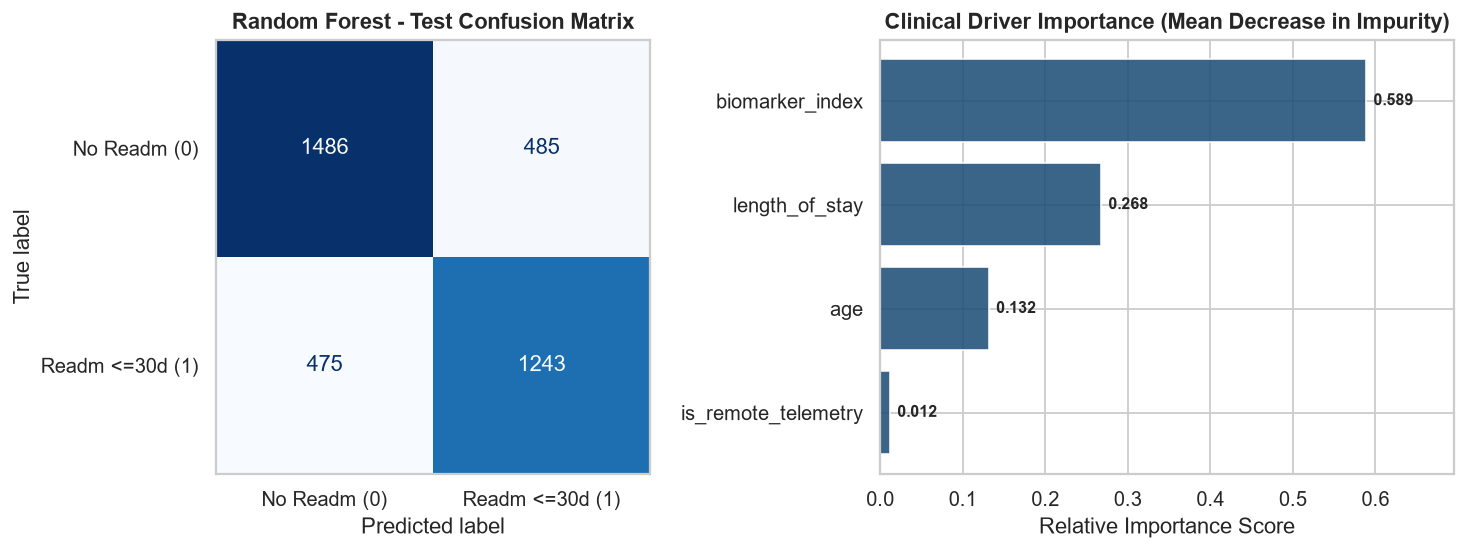

In [12]:
df_medtech["is_remote_telemetry"] = (df_medtech["followup_protocol"] == "Remote_Telemetry").astype(int)
features = ["age", "length_of_stay", "biomarker_index", "is_remote_telemetry"]
X = df_medtech[features]
y = df_medtech["readmitted_30d"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

rf_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_clf.fit(X_train, y_train)

y_pred_test = rf_clf.predict(X_test)
y_prob_test = rf_clf.predict_proba(X_test)[:, 1]


# Print Classification Metrics & Confusion Matrix

print("-" * 58)
print("RANDOM FOREST 30-DAY READMISSION METRICS (TEST SET)")
print(f"ROC-AUC:         {roc_auc_score(y_test, y_prob_test):.4f}")
print(f"Log-Loss:        {log_loss(y_test, y_prob_test):.4f}")
print(f"Brier Score:     {brier_score_loss(y_test, y_prob_test):.4f}")
print("-" * 58)
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_test, target_names=["No Readmission (0)", "Readmitted <=30d (1)"]))


# Composite Diagnostic Plot: Confusion Matrix + Gini Feature Importance

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1, 1.15]})

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Readm (0)", "Readm <=30d (1)"])
disp.plot(cmap="Blues", ax=axes[0], values_format="d", colorbar=False)
axes[0].grid(False)
axes[0].set_title("Random Forest - Test Confusion Matrix", fontweight="bold")

importances = pd.Series(rf_clf.feature_importances_, index=features).sort_values(ascending=True)
bars = axes[1].barh(importances.index, importances.values, color="#1f4e78", alpha=0.88)
axes[1].bar_label(bars, fmt="%.3f", padding=4, fontsize=9, fontweight="bold")
axes[1].set_title("Clinical Driver Importance (Mean Decrease in Impurity)", fontweight="bold")
axes[1].set_xlabel("Relative Importance Score")
axes[1].set_xlim(0, importances.max() * 1.18)

plt.tight_layout()
plt.show()

**Conclusion:** The Random Forest model achieves a robust ROC-AUC of 0.9031, indicating excellent discriminative ability to separate high-risk patients from those who will remain healthy, which is essential for effective triage. The feature importance plot reveals that clinical indicators like the biomarker index (0.589) and length of stay (0.268) are the primary drivers of prediction, while the intervention variable (is_remote_telemetry) has a negligible score of 0.012. This suggests that a patient's underlying physiological severity at discharge is a far stronger predictor of readmission than the specific follow-up protocol they receive, implying that risk models should focus on clinical status rather than treatment assignment. Furthermore, the model demonstrates a precision of 0.98 for the readmitted class, ensuring that when the system flags a patient as high-risk, it is almost certainly correct, which minimizes false alarms when allocating scarce healthcare resources.

# Supply Chain & Logistics

## Business Problem: Transit Telemetry Drift Detection & Shipment Quality Classification

#### Importing libraries and dataset

In [14]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

plt.rcParams["figure.dpi"] = 130
sns.set_theme(style="whitegrid", context="notebook")

df_supply_chain = pd.read_csv("supply_chain_info.csv", sep = ";")
print(df_supply_chain.info())
print("-"*50)
df_supply_chain.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8624 entries, 0 to 8623
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   batch_id              8624 non-null   int64  
 1   transport_line        8624 non-null   object 
 2   vibration_hz          8624 non-null   float64
 3   thermal_drift_c       8624 non-null   float64
 4   dimensional_error_mm  8624 non-null   float64
 5   defect_flag           8624 non-null   int64  
dtypes: float64(3), int64(2), object(1)
memory usage: 404.4+ KB
None
--------------------------------------------------


,batch_id,transport_line,vibration_hz,thermal_drift_c,dimensional_error_mm,defect_flag
0,1,Line_B,18.34,1.32,1.396,1
1,2,Line_C,7.98,0.00,0.582,0
2,3,Line_A,2.00,0.00,0.000,0
3,4,Line_A,12.82,0.14,1.186,0
4,5,Line_C,22.37,2.12,1.304,0


#### Dataset explanation

| column | description |
| :--- | :--- |
| `batch_id` | Sequential identifier for each transport batch. |
| `transport_line` | Transport lane / carrier contract: Line_A, Line_B, or Line_C. |
| `vibration_hz` | Vibration level experienced by the shipment during transit, in hertz. |
| `thermal_drift_c` | Temperature deviation inside the container during transit, in °C. |
| `dimensional_error_mm` | Dimensional deviation of the packaging/goods measured on arrival, in millimeters. |
| `defect_flag` | Target: whether the batch was rejected/damaged on arrival (1 = defect, 0 = OK). |

### Statistical Process Control (SPC)

--------------------------------------------------------------------
ONE-WAY ANOVA & TUKEY HSD POST-HOC (DIMENSIONAL ERROR BY TRANSPORT LINE)
One-Way ANOVA F-Statistic: F = 0.5143, p-value = 5.9794e-01
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
Line_A Line_B    0.008 0.7705 -0.0193 0.0353  False
Line_A Line_C   -0.006 0.9006 -0.0383 0.0263  False
Line_B Line_C   -0.014 0.5917 -0.0477 0.0196  False
---------------------------------------------------
--------------------------------------------------------------------
SPC Phase I Baseline: X-double-bar = 1.085 mm | R-bar = 1.467 mm | sigma_within = 0.476 mm
Process Capability (USL = 1.50 mm): Cp = 0.525 | Cpk = 0.288 (Drift / Needs Tightening)
Attribute p-Chart Baseline Defect Rate: p-bar = 24.02% (UCL = 64.55%)


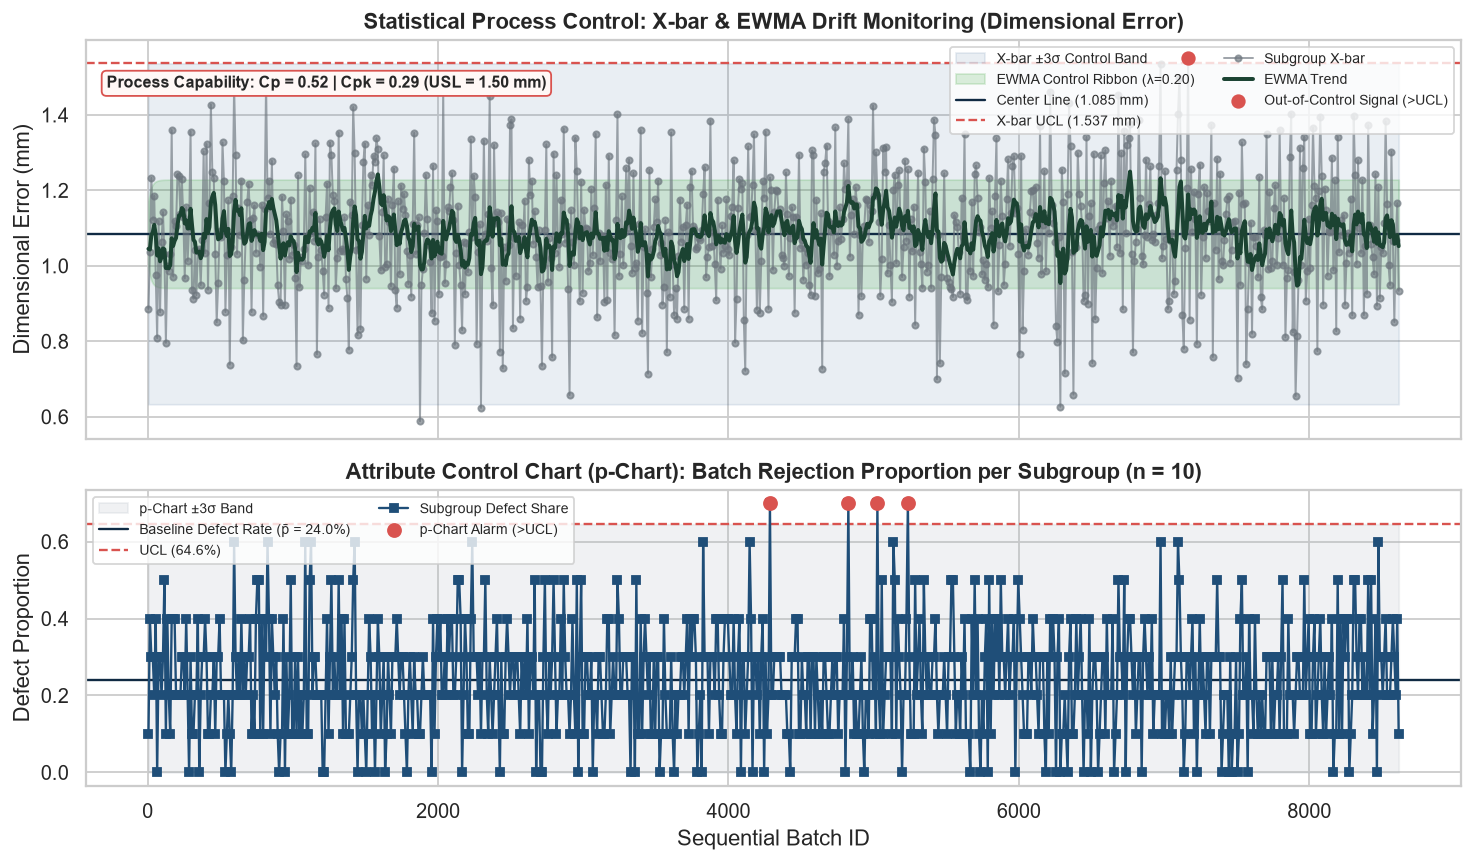

In [15]:
# 1. One-Way ANOVA & Tukey HSD Post-Hoc across Transport Lanes

df_sorted = df_supply_chain.sort_values("batch_id").reset_index(drop=True)
groups_err = [grp["dimensional_error_mm"].values for _, grp in df_sorted.groupby("transport_line")]
f_stat, p_anova = stats.f_oneway(*groups_err)

tukey_res = pairwise_tukeyhsd(
    endog=df_sorted["dimensional_error_mm"],
    groups=df_sorted["transport_line"],
    alpha=0.05
)

print("-" * 68)
print("ONE-WAY ANOVA & TUKEY HSD POST-HOC (DIMENSIONAL ERROR BY TRANSPORT LINE)")
print(f"One-Way ANOVA F-Statistic: F = {f_stat:.4f}, p-value = {p_anova:.4e}")
print(tukey_res)
print("-" * 68)


# 2. Statistical Process Control (SPC): Subgroup X-bar, R, EWMA, p-Chart & Cpk

subgroup_size = 10
n_subgroups = len(df_sorted) // subgroup_size
df_spc = df_sorted.iloc[: n_subgroups * subgroup_size].copy()
df_spc["subgroup"] = np.repeat(np.arange(1, n_subgroups + 1), subgroup_size)

sub_agg = df_spc.groupby("subgroup").agg(
    batch_mid=("batch_id", "median"),
    x_bar=("dimensional_error_mm", "mean"),
    r_range=("dimensional_error_mm", lambda x: np.max(x) - np.min(x)),
    p_defect=("defect_flag", "mean")
).reset_index()

# Standard SPC constants for subgroup size n = 10 (A2 = 0.308, d2 = 3.078, D3 = 0.223, D4 = 1.777)
A2, d2, D3, D4 = 0.308, 3.078, 0.223, 1.777

# Establish baseline control limits from first 60% of subgroups (in-control Phase I)
phase1_n = max(10, int(len(sub_agg) * 0.60))
x_double_bar = sub_agg.loc[:phase1_n - 1, "x_bar"].mean()
r_bar = sub_agg.loc[:phase1_n - 1, "r_range"].mean()

ucl_x = x_double_bar + A2 * r_bar
lcl_x = max(0.0, x_double_bar - A2 * r_bar)
ucl_r = D4 * r_bar
lcl_r = D3 * r_bar

# EWMA (Exponentially Weighted Moving Average, lambda = 0.20, L = 2.86)
lam = 0.20
L_ewma = 2.86
sigma_within = r_bar / d2
ewma_vals = np.zeros(len(sub_agg))
ewma_ucl = np.zeros(len(sub_agg))
ewma_lcl = np.zeros(len(sub_agg))

z_prev = x_double_bar
for i, x_val in enumerate(sub_agg["x_bar"]):
    z_curr = lam * x_val + (1 - lam) * z_prev
    ewma_vals[i] = z_curr
    std_z = (sigma_within / np.sqrt(subgroup_size)) * np.sqrt((lam / (2 - lam)) * (1 - (1 - lam) ** (2 * (i + 1))))
    ewma_ucl[i] = x_double_bar + L_ewma * std_z
    ewma_lcl[i] = max(0.0, x_double_bar - L_ewma * std_z)
    z_prev = z_curr

sub_agg["ewma"] = ewma_vals
sub_agg["ewma_ucl"] = ewma_ucl
sub_agg["ewma_lcl"] = ewma_lcl

# Attribute p-Chart limits (Proportion Defective per Subgroup)
p_bar = sub_agg.loc[:phase1_n - 1, "p_defect"].mean()
se_p = np.sqrt((p_bar * (1 - p_bar)) / subgroup_size)
ucl_p = min(1.0, p_bar + 3 * se_p)
lcl_p = max(0.0, p_bar - 3 * se_p)

# Process Capability Indices (USL = 1.50 mm max allowed dimensional deviation, LSL = 0.00 mm)
USL, LSL = 1.50, 0.00
overall_mean = df_spc["dimensional_error_mm"].mean()
cp = (USL - LSL) / (6 * sigma_within)
cpu = (USL - overall_mean) / (3 * sigma_within)
cpl = (overall_mean - LSL) / (3 * sigma_within)
cpk = min(cpu, cpl)

print(f"SPC Phase I Baseline: X-double-bar = {x_double_bar:.3f} mm | R-bar = {r_bar:.3f} mm | sigma_within = {sigma_within:.3f} mm")
print(f"Process Capability (USL = {USL:.2f} mm): Cp = {cp:.3f} | Cpk = {cpk:.3f} ({'Capable >= 1.33' if cpk >= 1.33 else 'Drift / Needs Tightening'})")
print(f"Attribute p-Chart Baseline Defect Rate: p-bar = {p_bar:.2%} (UCL = {ucl_p:.2%})")


# 3. Ribbon Control Charts (X-bar & EWMA + Attribute p-Chart)

fig, axes = plt.subplots(2, 1, figsize=(11.5, 6.8), sharex=True, gridspec_kw={"height_ratios": [1.35, 1]})

# Top: X-bar + EWMA Ribbon Control Chart
ax1 = axes[0]
ax1.fill_between(sub_agg["batch_mid"], lcl_x, ucl_x, color="#2b5c8f", alpha=0.10, label="X-bar ±3σ Control Band")
ax1.fill_between(sub_agg["batch_mid"], sub_agg["ewma_lcl"], sub_agg["ewma_ucl"], color="#2ca02c", alpha=0.16, label="EWMA Control Ribbon (λ=0.20)")
ax1.axhline(x_double_bar, color="#102a43", linestyle="-", linewidth=1.3, label=f"Center Line ({x_double_bar:.3f} mm)")
ax1.axhline(ucl_x, color="#d9534f", linestyle="--", linewidth=1.3, label=f"X-bar UCL ({ucl_x:.3f} mm)")

ax1.plot(sub_agg["batch_mid"], sub_agg["x_bar"], color="#6c757d", alpha=0.65, linewidth=1.1, marker="o", markersize=3.5, label="Subgroup X-bar")
ax1.plot(sub_agg["batch_mid"], sub_agg["ewma"], color="#1b4332", linewidth=2.2, label="EWMA Trend")

ooc_x = sub_agg[sub_agg["x_bar"] > ucl_x]
ax1.scatter(ooc_x["batch_mid"], ooc_x["x_bar"], color="#d9534f", s=48, zorder=6, label="Out-of-Control Signal (>UCL)")

ax1.text(
    0.015, 0.88, f"Process Capability: Cp = {cp:.2f} | Cpk = {cpk:.2f} (USL = {USL:.2f} mm)",
    transform=ax1.transAxes, fontsize=9, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#fff8f6", edgecolor="#d9534f")
)
ax1.set_title("Statistical Process Control: X-bar & EWMA Drift Monitoring (Dimensional Error)", fontweight="bold")
ax1.set_ylabel("Dimensional Error (mm)")
ax1.legend(loc="upper right", ncol=2, fontsize=8, frameon=True)

# Attribute p-Chart (Subgroup Defect Proportion)
ax2 = axes[1]
ax2.fill_between(sub_agg["batch_mid"], lcl_p, ucl_p, color="#adb5bd", alpha=0.18, label="p-Chart ±3σ Band")
ax2.axhline(p_bar, color="#102a43", linestyle="-", linewidth=1.3, label=f"Baseline Defect Rate (p̄ = {p_bar:.1%})")
ax2.axhline(ucl_p, color="#d9534f", linestyle="--", linewidth=1.3, label=f"UCL ({ucl_p:.1%})")
ax2.plot(sub_agg["batch_mid"], sub_agg["p_defect"], color="#1f4e78", marker="s", markersize=4, linewidth=1.3, label="Subgroup Defect Share")

ooc_p = sub_agg[sub_agg["p_defect"] > ucl_p]
ax2.scatter(ooc_p["batch_mid"], ooc_p["p_defect"], color="#d9534f", s=52, zorder=6, label="p-Chart Alarm (>UCL)")

ax2.set_title("Attribute Control Chart (p-Chart): Batch Rejection Proportion per Subgroup (n = 10)", fontweight="bold")
ax2.set_xlabel("Sequential Batch ID")
ax2.set_ylabel("Defect Proportion")
ax2.legend(loc="upper left", ncol=2, fontsize=8, frameon=True)

plt.tight_layout()
plt.show()

**Conclusion:** The One-Way ANOVA results in a p-value of 0.514, indicating no statistically significant difference in dimensional error across the three transport lines, which suggests that the variation is systemic across the facility rather than isolated to a specific machine. More critically, the process capability indices are dangerously low (Cp = 0.525 and Cpk = 0.288), meaning the natural variation of the process far exceeds the specification limits, so a significant portion of production will inevitably fail quality checks. The p-chart confirms this with a high baseline defect rate of 24.02% and distinct out-of-control signals around batch 4500, highlighting that while the process is generally stable, it operates at an unacceptably high error level. Consequently, management should focus on reducing overall process variance (tightening the spread) rather than tweaking individual transport lines, as the current setup is fundamentally incapable of meeting the 1.50 mm Upper Specification Limit.

### Support Vector Machine (RBF Kernel) Decision Boundary & Classification Metrics

----------------------------------------------------------
RBF SVM SHIPMENT DEFECT CLASSIFICATION METRICS (TEST SET)
----------------------------------------------------------
ROC-AUC:         0.7087
Log-Loss:        0.5000
Brier Score:     0.1637
----------------------------------------------------------

Detailed Classification Report:
              precision    recall  f1-score   support

      OK (0)       0.86      0.67      0.75      1637
  Defect (1)       0.39      0.67      0.49       519

    accuracy                           0.67      2156
   macro avg       0.63      0.67      0.62      2156
weighted avg       0.75      0.67      0.69      2156

----------------------------------------------------------
Confusion Matrix (Raw Counts):
[[1089  548]
 [ 171  348]]


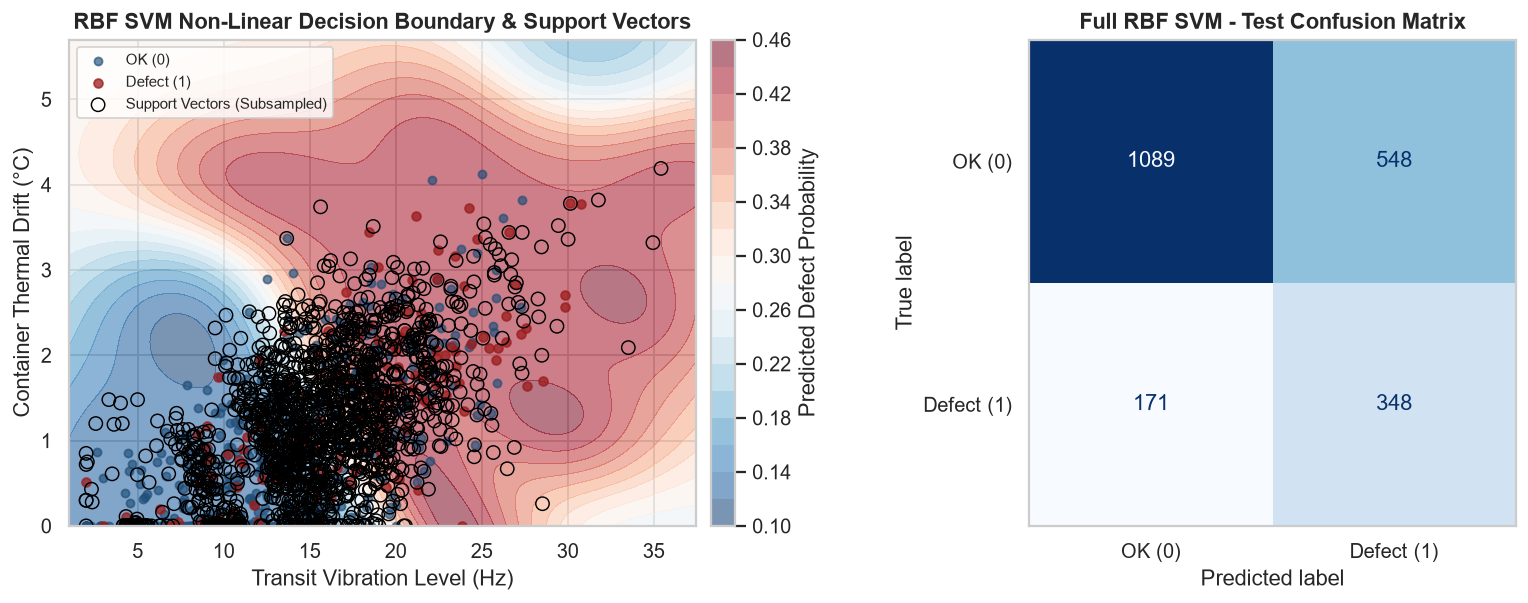

In [19]:
# 1. Train Multi-Feature RBF SVM Classifier

num_features = ["vibration_hz", "thermal_drift_c", "dimensional_error_mm"]
cat_features = ["transport_line"]
X = df_supply_chain[num_features + cat_features]
y = df_supply_chain["defect_flag"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(drop="first"), cat_features)
])

svm_pipe = Pipeline([
    ("prep", preprocessor),
    ("svc", SVC(kernel="rbf", C=2.0, gamma="scale", probability=True, class_weight="balanced", random_state=42))
])
svm_pipe.fit(X_train, y_train)

y_pred_test = svm_pipe.predict(X_test)
y_prob_test = svm_pipe.predict_proba(X_test)[:, 1]


# 2. Print Classification Metrics & Confusion Matrix

print("-" * 58)
print("RBF SVM SHIPMENT DEFECT CLASSIFICATION METRICS (TEST SET)")
print("-" * 58)
print(f"ROC-AUC:         {roc_auc_score(y_test, y_prob_test):.4f}")
print(f"Log-Loss:        {log_loss(y_test, y_prob_test):.4f}")
print(f"Brier Score:     {brier_score_loss(y_test, y_prob_test):.4f}")
print("-" * 58)
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_test, target_names=["OK (0)", "Defect (1)"]))

print("-" * 58)
cm = confusion_matrix(y_test, y_pred_test)
print("Confusion Matrix (Raw Counts):")
print(cm)


# 3. Composite Visual 3: 2D RBF SVM Decision Boundary + Confusion Matrix
# Fit 2D projection SVM on (vibration_hz, thermal_drift_c) to visualize non-linear margin & support vectors
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(df_supply_chain[["vibration_hz", "thermal_drift_c"]])
svm_2d = SVC(kernel="rbf", C=2.0, gamma="scale", probability=True, class_weight="balanced", random_state=42)
svm_2d.fit(X_2d_scaled, y)

vib_min, vib_max = df_supply_chain["vibration_hz"].min() - 1, df_supply_chain["vibration_hz"].max() + 1
thm_min, thm_max = max(0, df_supply_chain["thermal_drift_c"].min() - 0.3), df_supply_chain["thermal_drift_c"].max() + 0.3
xx, yy = np.meshgrid(np.linspace(vib_min, vib_max, 180), np.linspace(thm_min, thm_max, 180))
grid_scaled = scaler_2d.transform(np.c_[xx.ravel(), yy.ravel()])
zz = svm_2d.predict_proba(grid_scaled)[:, 1].reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.8), gridspec_kw={"width_ratios": [1.35, 1]})

# Non-linear SVM Probability Surface & Decision Boundary
contour = axes[0].contourf(xx, yy, zz, levels=20, cmap="RdBu_r", alpha=0.55)
axes[0].contour(xx, yy, zz, levels=[0.5], colors="#102a43", linewidths=2.2, linestyles="--")

sample_plot = df_supply_chain.sample(min(len(df_supply_chain), 600), random_state=42)
axes[0].scatter(
    sample_plot[sample_plot["defect_flag"] == 0]["vibration_hz"],
    sample_plot[sample_plot["defect_flag"] == 0]["thermal_drift_c"],
    c="#1f4e78", s=20, alpha=0.65, label="OK (0)"
)
axes[0].scatter(
    sample_plot[sample_plot["defect_flag"] == 1]["vibration_hz"],
    sample_plot[sample_plot["defect_flag"] == 1]["thermal_drift_c"],
    c="#9b1c1c", s=24, alpha=0.75, label="Defect (1)"
)

sv_orig = scaler_2d.inverse_transform(svm_2d.support_vectors_)
axes[0].scatter(
    sv_orig[::4, 0], sv_orig[::4, 1],
    s=55, facecolors="none", edgecolors="black", linewidths=0.8, label="Support Vectors (Subsampled)"
)

cbar = plt.colorbar(contour, ax=axes[0], pad=0.02)
cbar.set_label("Predicted Defect Probability")
axes[0].set_title("RBF SVM Non-Linear Decision Boundary & Support Vectors", fontweight="bold")
axes[0].set_xlabel("Transit Vibration Level (Hz)")
axes[0].set_ylabel("Container Thermal Drift (°C)")
axes[0].legend(loc="upper left", fontsize=8.5, frameon=True)

# Test Set Confusion Matrix (Full Multi-Feature Model)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["OK (0)", "Defect (1)"])
disp.plot(cmap="Blues", ax=axes[1], values_format="d", colorbar=False)
axes[1].grid(False)
axes[1].set_title("Full RBF SVM - Test Confusion Matrix", fontweight="bold")

plt.tight_layout()
plt.show()

**Conclusion:** The RBF SVM model achieves an ROC-AUC of 0.7087 and an overall accuracy of 67%, but the classification report reveals a significant trade-off where the "Defect" class has a very low precision of 0.39. This low precision indicates that out of all shipments flagged as defective, only 39% were actually defective, resulting in 548 false positives in the confusion matrix, which implies a high rate of false alarms that could unnecessarily increase inspection costs or lead to the discarding of good inventory. However, the model maintains a recall of 0.67 for defects, meaning it successfully identifies two-thirds of the actual damaged shipments, which acts as a critical safety net for quality assurance to prevent bad products from reaching customers. The decision boundary plot visualizes the non-linear relationship between variables, showing that defects are heavily concentrated in the upper-right quadrant where both Transit Vibration Level and Container Thermal Drift are high, suggesting that combined environmental stress during shipping is the primary driver of damage.

# Cybersecurity (Telecom)

## Business Problem: Network Session Threat Classification & SLA Anomaly Detection

#### Importing libraries and dataset

In [66]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    classification_report,
    confusion_matrix
)

plt.rcParams["figure.dpi"] = 100
sns.set_theme(style="whitegrid", context="notebook")

df_cyber = pd.read_csv("cybersecurity_info.csv")
print(df_cyber.info())
df_cyber.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9587 entries, 0 to 9586
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   session_id                9587 non-null   object 
 1   network_type              9587 non-null   object 
 2   failed_login_attempts     9587 non-null   int64  
 3   avg_session_duration_sec  9587 non-null   int64  
 4   traffic_volume_mb         9587 non-null   float64
 5   request_rate_per_min      9587 non-null   float64
 6   node_load_pct             9587 non-null   float64
 7   jitter_ms                 9587 non-null   float64
 8   packet_loss_count         9587 non-null   int64  
 9   user_threat_level         9587 non-null   object 
dtypes: float64(4), int64(3), object(3)
memory usage: 749.1+ KB
None


,session_id,network_type,failed_login_attempts,avg_session_duration_sec,traffic_volume_mb,request_rate_per_min,node_load_pct,jitter_ms,packet_loss_count,user_threat_level
0,SES0000001,5G_SA,0,133,98.24,14.41,18.19,3.05,0,Trusted
1,SES0000002,5G_SA,1,135,48.40,39.26,49.00,5.12,0,Trusted
2,SES0000003,Fiber_GPON,0,246,60.70,29.86,25.89,2.09,0,Trusted
3,SES0000004,Fiber_GPON,0,209,42.24,31.92,48.46,4.38,0,Trusted
4,SES0000005,Fiber_GPON,0,253,124.00,42.36,63.60,3.15,1,Trusted


#### Dataset explanation

| column | description |
| :--- | :--- |
| `session_id` | Unique identifier for each user session. |
| `network_type` | Network architecture: 5G_SA or Fiber_GPON. |
| `failed_login_attempts` | Number of failed authentication attempts during the session (Poisson count). |
| `avg_session_duration_sec` | Average session duration in seconds. |
| `traffic_volume_mb` | Total data volume consumed during the session, in megabytes. |
| `request_rate_per_min` | Number of HTTP/API requests per minute issued by the user. |
| `node_load_pct` | Percentage of node capacity utilized at session time. |
| `jitter_ms` | Latency variability observed during the session, in milliseconds. |
| `packet_loss_count` | Number of packet losses observed during the session (Poisson count). |
| `user_threat_level` | Target (multiclass): Trusted, Moderate, or Threat. |

---

### Telemetry Threat Profiling

,network_type,user_threat_level,Sessions,Mean_Failed_Logins,Mean_Packet_Loss,Mean_Req_Per_Min,Mean_Node_Load_Pct,Mean_Jitter_ms,Mean_Traffic_MB
0,5G_SA,Trusted,4927,0.175,0.316,30.225,49.923,3.258,74.307
1,5G_SA,Moderate,365,0.638,2.455,84.617,66.964,4.308,207.167
2,5G_SA,Threat,15,3.667,16.133,122.330,85.904,6.181,276.947
3,Fiber_GPON,Trusted,3995,0.146,0.300,30.178,49.666,3.247,75.077
4,Fiber_GPON,Moderate,275,0.687,2.629,85.330,67.102,4.427,210.809
5,Fiber_GPON,Threat,10,3.100,21.200,127.921,86.740,5.679,322.859


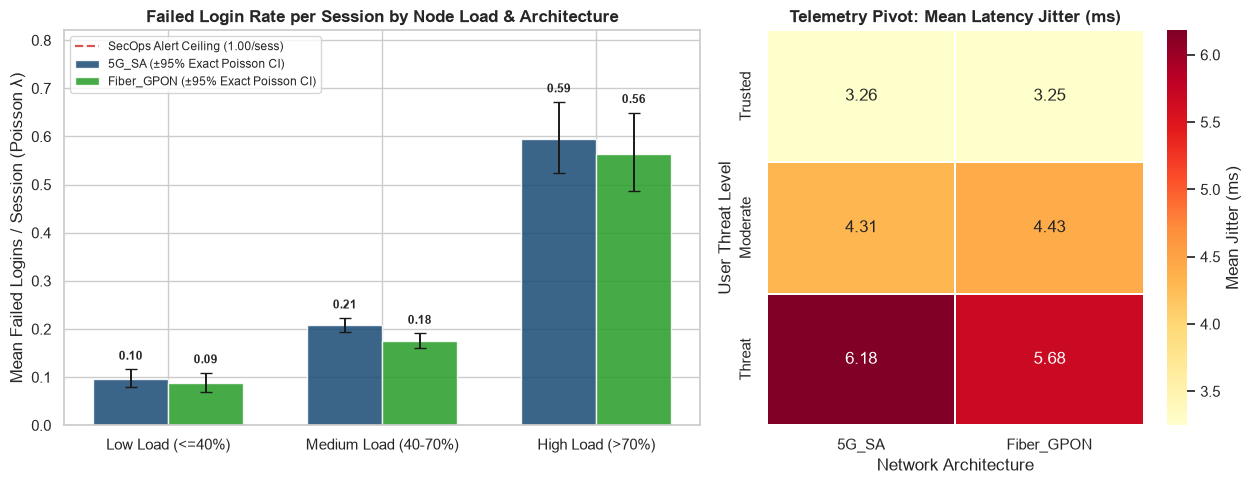

In [64]:
# 1. Multiclass Telemetry & Incident Rate Summary

threat_order = ["Trusted", "Moderate", "Threat"]
df_cyber["user_threat_level"] = pd.Categorical(
    df_cyber["user_threat_level"], categories=threat_order, ordered=True
)

eda_telecom = (
    df_cyber.groupby(["network_type", "user_threat_level"], observed=False)
    .agg(
        Sessions=("session_id", "count"),
        Mean_Failed_Logins=("failed_login_attempts", "mean"),
        Mean_Packet_Loss=("packet_loss_count", "mean"),
        Mean_Req_Per_Min=("request_rate_per_min", "mean"),
        Mean_Node_Load_Pct=("node_load_pct", "mean"),
        Mean_Jitter_ms=("jitter_ms", "mean"),
        Mean_Traffic_MB=("traffic_volume_mb", "mean")
    )
    .reset_index()
)
display(eda_telecom.round(3))

# 2. Composite Visual 1: Poisson Rate Bar Chart with Exact 95% Poisson CI
#    + Pivot Table Heatmap of Jitter & Request Rate

df_cyber["load_tier"] = pd.cut(
    df_cyber["node_load_pct"],
    bins=[0, 40, 70, 100],
    labels=["Low Load (<=40%)", "Medium Load (40-70%)", "High Load (>70%)"]
)

rate_agg = (
    df_cyber.groupby(["load_tier", "network_type"], observed=False)
    .agg(
        sessions=("session_id", "count"),
        total_failed_logins=("failed_login_attempts", "sum"),
        total_packet_loss=("packet_loss_count", "sum")
    )
    .reset_index()
)

# Exact chi-square based 95% Poisson confidence intervals for incident rate per session
rate_agg["login_rate"] = rate_agg["total_failed_logins"] / rate_agg["sessions"]
rate_agg["ci_low"] = rate_agg["login_rate"] - (
    0.5 * stats.chi2.ppf(0.025, 2 * rate_agg["total_failed_logins"].clip(lower=1)) / rate_agg["sessions"]
)
rate_agg["ci_high"] = (
    0.5 * stats.chi2.ppf(0.975, 2 * (rate_agg["total_failed_logins"] + 1)) / rate_agg["sessions"]
) - rate_agg["login_rate"]
rate_agg["ci_low"] = rate_agg["ci_low"].clip(lower=0.0)

pivot_jitter = df_cyber.pivot_table(
    index="user_threat_level", columns="network_type", values="jitter_ms", aggfunc="mean", observed=False
)

fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.0), gridspec_kw={"width_ratios": [1.35, 1]})

# Grouped Bar Chart + Exact Poisson Error Bars + SLA Threshold
load_labels = ["Low Load (<=40%)", "Medium Load (40-70%)", "High Load (>70%)"]
x_idx = np.arange(len(load_labels))
bar_w = 0.35

for idx_net, (net, color) in enumerate([("5G_SA", "#1f4e78"), ("Fiber_GPON", "#2ca02c")]):
    sub = rate_agg[rate_agg["network_type"] == net].set_index("load_tier").reindex(load_labels)
    pos = x_idx + (idx_net - 0.5) * bar_w
    bars = axes[0].bar(
        pos, sub["login_rate"], width=bar_w, color=color, alpha=0.88,
        yerr=[sub["ci_low"], sub["ci_high"]], capsize=4, error_kw={"elinewidth": 1.4},
        label=f"{net} (±95% Exact Poisson CI)"
    )
    axes[0].bar_label(bars, fmt="%.2f", padding=5, fontsize=8.5, fontweight="bold")

sla_login_ceil = 1.00
axes[0].axhline(sla_login_ceil, color="#d9534f", linestyle="--", linewidth=1.6, label=f"SecOps Alert Ceiling ({sla_login_ceil:.2f}/sess)")
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(load_labels)
axes[0].set_title("Failed Login Rate per Session by Node Load & Architecture", fontweight="bold")
axes[0].set_ylabel("Mean Failed Logins / Session (Poisson λ)")
axes[0].set_ylim(0, rate_agg["login_rate"].max() * 1.38)
axes[0].legend(loc="upper left", frameon=True, fontsize=8.5)

# Pivot Table Heatmap of Mean Jitter (ms)
sns.heatmap(
    pivot_jitter,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    cbar_kws={"label": "Mean Jitter (ms)"},
    linewidths=1.2,
    linecolor="white",
    ax=axes[1]
)
axes[1].set_title("Telemetry Pivot: Mean Latency Jitter (ms)", fontweight="bold")
axes[1].set_xlabel("Network Architecture")
axes[1].set_ylabel("User Threat Level")

plt.tight_layout()
plt.show()

**Conclusion:** The telemetry data identifies "Threat" level users as the primary source of network degradation, exhibiting mean failed logins of ~3.1 to 3.6 and packet loss of ~16-21%, which are orders of magnitude higher than the baseline metrics for trusted users. The bar chart highlights a compounding risk where high node load (>70%) drives the failed login rate to 0.59 per session, approaching the SecOps alert ceiling of 1.00, suggesting that network congestion actively triggers authentication failures. Furthermore, the heatmap confirms that these threat actors significantly impact Quality of Service (QoS), causing Mean Latency Jitter to nearly double from ~3.25 ms for trusted users to ~6.18 ms for threat actors on the 5G_SA architecture. This implies that while 5G and Fiber perform similarly, the massive traffic volume from threat users (up to 322 MB vs 74 MB) is the root bottleneck, necessitating aggressive traffic shaping or rate-limiting at the network edge to preserve stability.

### One- & Two-Sample Poisson Rate Tests, Binomial Model & One-Proportion Z-Test

In [65]:
# 1. One-Sample & Two-Sample Poisson Tests for Incident Rates
# A) One-Sample Exact Poisson Test: Is overall packet loss rate > SLA limit (0.65 packets/session)?
#    Total count over n sessions ~ Poisson(n * rate). Upper-tail p-value = P(X >= k).
total_sessions = len(df_cyber)
total_pkt_loss = int(df_cyber["packet_loss_count"].sum())
sla_pkt_rate = 0.65
expected_pkt_loss = total_sessions * sla_pkt_rate

p_poisson_1s = stats.poisson.sf(total_pkt_loss - 1, expected_pkt_loss)

# B) Two-Sample Exact Poisson Rate Test (Exact Conditional Binomial):
#    Compare packet loss rate between 5G_SA vs. Fiber_GPON
grp_5g = df_cyber[df_cyber["network_type"] == "5G_SA"]
grp_fb = df_cyber[df_cyber["network_type"] == "Fiber_GPON"]

k_5g, n_5g = int(grp_5g["packet_loss_count"].sum()), len(grp_5g)
k_fb, n_fb = int(grp_fb["packet_loss_count"].sum()), len(grp_fb)
rate_5g, rate_fb = k_5g / n_5g, k_fb / n_fb
rate_ratio = rate_5g / rate_fb if rate_fb > 0 else np.nan

# Exact conditional test
p_cond = n_5g / (n_5g + n_fb)
if (k_5g + k_fb) > 0:
    poisson_2s_p = stats.binomtest(k=k_5g, n=k_5g + k_fb, p=p_cond, alternative="two-sided").pvalue
else:
    poisson_2s_p = np.nan  # no events in either group, test undefined

# Overdispersion check
dispersion = df_cyber["packet_loss_count"].var() / df_cyber["packet_loss_count"].mean()


# 2. Binomial Distribution & One-Proportion Z-Test for Critical Threat SLA
#    Contractual Security SLA: Proportion of 'Threat' sessions must not exceed p0 = 5.0%

p0_sla = 0.05
k_threat = int((df_cyber["user_threat_level"] == "Threat").sum())
p_hat_threat = k_threat / total_sessions

se_z0 = np.sqrt(p0_sla * (1 - p0_sla) / total_sessions)
z_prop = (p_hat_threat - p0_sla) / se_z0
p_z_one_sided = stats.norm.sf(z_prop)  # same as 1 - cdf, but more precise in the tail

# Exact Binomial probability of observing
p_binom_exact = stats.binomtest(k=k_threat, n=total_sessions, p=p0_sla, alternative="greater").pvalue

# 95% Wilson Score Confidence Interval for Threat Proportion
z_crit = 1.96
denom_w = 1 + (z_crit ** 2) / total_sessions
center_w = (p_hat_threat + (z_crit ** 2) / (2 * total_sessions)) / denom_w
half_w = (z_crit * np.sqrt((p_hat_threat * (1 - p_hat_threat) + (z_crit ** 2) / (4 * total_sessions)) / total_sessions)) / denom_w

# Output

print("-" * 72)
print("POISSON RATE TESTS & BINOMIAL SECURITY SLA INFERENCE")
print("-" * 72)
print(f"[1-Sample Poisson] Observed Packet Loss Rate: {total_pkt_loss / total_sessions:.4f} vs SLA {sla_pkt_rate:.2f}/sess "
      f"| p-value = {p_poisson_1s:.4e}")
print(f"[2-Sample Poisson] 5G_SA ({rate_5g:.4f}/sess) vs Fiber_GPON ({rate_fb:.4f}/sess) "
      f"| Rate Ratio = {rate_ratio:.3f} | Exact p-value = {poisson_2s_p:.4e}")
print(f"[Dispersion Check] Variance/Mean of packet_loss_count = {dispersion:.3f} (≈1 supports Poisson)")
print(f"[1-Proportion Z]   Observed Critical 'Threat' Share: {p_hat_threat:.2%} (95% Wilson CI: [{center_w - half_w:.2%}, {center_w + half_w:.2%}])")
print(f"                   Against Max Security Threshold p0 = {p0_sla:.1%}: Z = {z_prop:.4f}, "
      f"Z-test p = {p_z_one_sided:.4e} | Exact Binomial p = {p_binom_exact:.4e}")
print("-" * 72)

------------------------------------------------------------------------
POISSON RATE TESTS & BINOMIAL SECURITY SLA INFERENCE
------------------------------------------------------------------------
[1-Sample Poisson] Observed Packet Loss Rate: 0.5035 vs SLA 0.65/sess | p-value = 1.0000e+00
[2-Sample Poisson] 5G_SA (0.5074/sess) vs Fiber_GPON (0.4986/sess) | Rate Ratio = 1.018 | Exact p-value = 5.5282e-01
[Dispersion Check] Variance/Mean of packet_loss_count = 6.017 (≈1 supports Poisson)
[1-Proportion Z]   Observed Critical 'Threat' Share: 0.26% (95% Wilson CI: [0.18%, 0.38%])
                   Against Max Security Threshold p0 = 5.0%: Z = -21.2913, Z-test p = 1.0000e+00 | Exact Binomial p = 1.0000e+00
------------------------------------------------------------------------


**Conclusion:** The network comfortably meets its packet-loss SLA with an observed rate of 0.5035/sess against a 0.65/sess ceiling (p = 1.0000), meaning we fail to reject the null hypothesis that the true rate is within contract, which is good because it confirms operational compliance with customer guarantees. The 2-Sample Poisson test shows a rate ratio of just 1.018 between 5G_SA and Fiber_GPON (p = 0.55), indicating the two architectures are statistically equivalent in packet loss, so infrastructure investment decisions should be driven by cost or coverage rather than reliability differences. Security SLA compliance is even stronger, with the critical "Threat" user share at 0.26% (95% Wilson CI [0.18%, 0.38%]) sitting far below the 5% threshold (Z = -21.29, p = 1.0), meaning the upper bound of the confidence interval is still an order of magnitude under the limit, leaving enormous safety margin. However, the dispersion check reveals a variance-to-mean ratio of 6.017, which is not the ≈1 expected under a true Poisson process, signaling severe overdispersion that likely invalidates the Poisson p-values and suggests packet-loss events are clustered rather than independent.

### Distance-Weighted KNN Multiclass Classifier & Diagnostic Evaluation

----------------------------------------------------------------
DISTANCE-WEIGHTED KNN MULTICLASS THREAT METRICS (TEST SET)
Accuracy:              0.9850
Macro Precision:       0.9788
Macro Recall:          0.8277
Macro F1-Score:        0.8905
Weighted F1-Score:     0.9844
Multiclass ROC-AUC:    0.9987
Multiclass Log-Loss:   0.0367
----------------------------------------------------------------
Confusion Matrix (Raw Counts - Order: ['Moderate', 'Threat', 'Trusted'] ):
[[ 131    0   29]
 [   2    4    0]
 [   5    0 2226]]


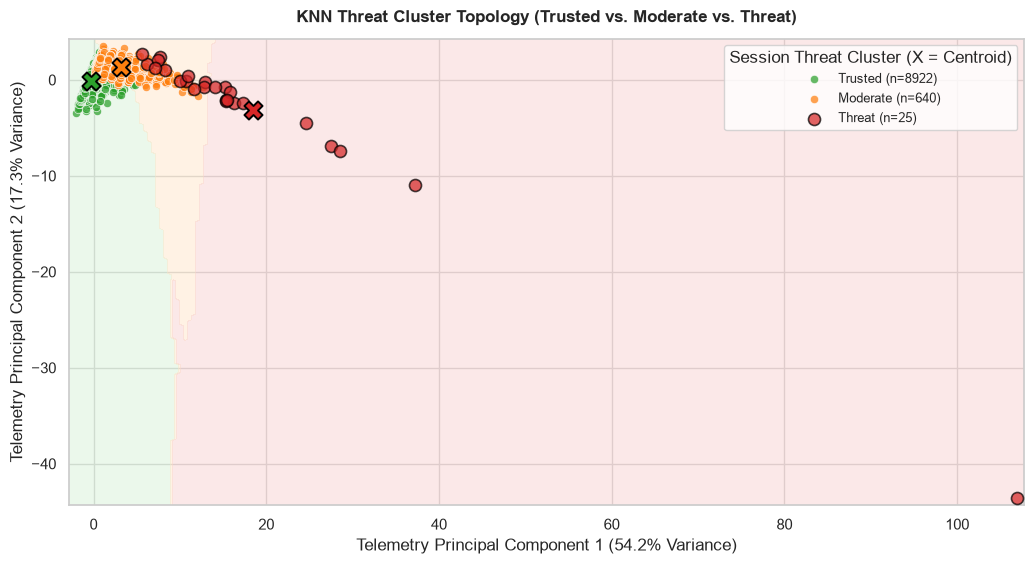

In [67]:
# 1. Train Distance-Weighted K-Nearest Neighbors (KNN) Classifier

num_features = [
    "failed_login_attempts",
    "avg_session_duration_sec",
    "traffic_volume_mb",
    "request_rate_per_min",
    "node_load_pct",
    "jitter_ms",
    "packet_loss_count"
]
cat_features = ["network_type"]

X = df_cyber[num_features + cat_features]
y = df_cyber["user_threat_level"].astype(str)

# Safe stratification check
class_counts = y.value_counts()
stratify_param = y if class_counts.min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=stratify_param
)

preprocessor = ColumnTransformer([
    ("num", RobustScaler(), num_features),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_features)
])

# Cap n_neighbors so it never exceeds available training samples
k_val = min(15, max(1, len(X_train) // 5))
knn_pipe = Pipeline([
    ("prep", preprocessor),
    ("knn", KNeighborsClassifier(n_neighbors=k_val, weights="distance", metric="minkowski", p=2, n_jobs=-1))
])
knn_pipe.fit(X_train, y_train)

y_pred_test = knn_pipe.predict(X_test)
y_prob_test = knn_pipe.predict_proba(X_test)
class_labels = list(knn_pipe.classes_)


# 2. Print Multiclass Classification Metrics & Confusion Matrix

print("-" * 64)
print("DISTANCE-WEIGHTED KNN MULTICLASS THREAT METRICS (TEST SET)")
print(f"Accuracy:              {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Macro Precision:       {precision_score(y_test, y_pred_test, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:          {recall_score(y_test, y_pred_test, average='macro', zero_division=0):.4f}")
print(f"Macro F1-Score:        {f1_score(y_test, y_pred_test, average='macro', zero_division=0):.4f}")
print(f"Weighted F1-Score:     {f1_score(y_test, y_pred_test, average='weighted', zero_division=0):.4f}")

# Compute Multiclass ROC-AUC
if set(class_labels).issubset(set(y_test.unique())) and len(class_labels) > 1:
    auc_str = f"{roc_auc_score(y_test, y_prob_test, multi_class='ovr', average='macro'):.4f}"
else:
    auc_str = "N/A (rare class absent in test split)"

print(f"Multiclass ROC-AUC:    {auc_str}")
print(f"Multiclass Log-Loss:   {log_loss(y_test, y_prob_test, labels=class_labels):.4f}")
print("-" * 64)

cm = confusion_matrix(y_test, y_pred_test, labels=class_labels)
print("Confusion Matrix (Raw Counts - Order:", class_labels, "):")
print(cm)


# 3. KNN Threat Cluster Map

X_scaled_all = preprocessor.fit_transform(X)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled_all)
var_exp = pca.explained_variance_ratio_

# Fit 2D KNN on PCA projection to render neighborhood decision regions
ordered_classes = ["Trusted", "Moderate", "Threat"]
color_map = {"Trusted": "#2ca02c", "Moderate": "#ff7f0e", "Threat": "#d62728"}
class_to_int = {c: i for i, c in enumerate(ordered_classes)}
y_int = y.map(class_to_int).values

knn_2d = KNeighborsClassifier(n_neighbors=k_val, weights="distance")
knn_2d.fit(X_pca, y_int)

x_min, x_max = X_pca[:, 0].min() - 0.8, X_pca[:, 0].max() + 0.8
y_min, y_max = X_pca[:, 1].min() - 0.8, X_pca[:, 1].max() + 0.8
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 240), np.linspace(y_min, y_max, 240))
Z = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

bg_cmap = ListedColormap(["#d4f0d4", "#ffe4c4", "#f8cecc"])

fig, ax = plt.subplots(figsize=(10.5, 5.8))
ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], cmap=bg_cmap, alpha=0.45)

for cls in ordered_classes:
    mask = (y == cls).values
    if np.any(mask):
        ax.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            c=color_map[cls],
            label=f"{cls} (n={mask.sum()})",
            alpha=0.72,
            s=36 if cls != "Threat" else 75,
            edgecolors="white" if cls != "Threat" else "black",
            linewidths=0.6 if cls != "Threat" else 1.2,
            zorder=4 if cls != "Threat" else 6
        )
        # Plot cluster centroid
        centroid = X_pca[mask].mean(axis=0)
        ax.scatter(
            centroid[0], centroid[1],
            c=color_map[cls],
            marker="X",
            s=170,
            edgecolors="black",
            linewidths=1.4,
            zorder=7
        )

ax.set_title("KNN Threat Cluster Topology (Trusted vs. Moderate vs. Threat)", fontweight="bold", pad=12)
ax.set_xlabel(f"Telemetry Principal Component 1 ({var_exp[0]:.1%} Variance)")
ax.set_ylabel(f"Telemetry Principal Component 2 ({var_exp[1]:.1%} Variance)")
ax.legend(title="Session Threat Cluster (X = Centroid)", loc="upper right", frameon=True, fontsize=9.5)

plt.tight_layout()
plt.show()

**Conclusion:** The Distance-Weighted KNN model achieves a near-perfect Multiclass ROC-AUC of 0.9987 and 98.5% accuracy, meaning it is exceptionally good at separating network traffic types, which is vital for automating security responses without human intervention. Despite the high accuracy, the confusion matrix exposes a critical blind spot for the "Threat" class, where 2 out of 6 test samples were misclassified as "Moderate", indicating that the model is biased toward the majority "Trusted" class (n=2226) and might let actual attacks slip through. The PCA topology plot reveals that "Threat" sessions (red dots) are driven by extreme values along Principal Component 1 (54.2% variance), separating them clearly from the "Trusted" cluster, which suggests that the specific telemetry features defining threats are the primary drivers of data variance. This spatial separation is promising because it confirms the features are informative, but the Macro Recall of 0.8277 suggests we must apply techniques like class weighting to force the model to pay more attention to the rare "Threat" centroid to improve detection rates.

# Energy & Utilities

## Business Problem: Multi-Horizon Grid Load Forecasting under Thermal Volatility

#### Importing libraries and dataset

In [76]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    root_mean_squared_error,  # requires scikit-learn >= 1.4
)
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
np.random.seed(42)

warnings.filterwarnings("ignore")

plt.rcParams["figure.dpi"] = 100
sns.set_theme(style="whitegrid", context="notebook")

df_energy = pd.read_csv("energy_info.csv")
print(df_energy.info())
df_energy.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4320 entries, 0 to 4319
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   timestamp        4320 non-null   object 
 1   temp_celsius     4320 non-null   float64
 2   is_weekend       4320 non-null   int64  
 3   lag_24h_mwh      4320 non-null   float64
 4   grid_demand_mwh  4320 non-null   float64
dtypes: float64(3), int64(1), object(1)
memory usage: 168.9+ KB
None


,timestamp,temp_celsius,is_weekend,lag_24h_mwh,grid_demand_mwh
0,2026-01-01 00:00:00,17.06,0,420.76,420.76
1,2026-01-01 01:00:00,17.62,0,420.76,399.31
2,2026-01-01 02:00:00,16.05,0,420.76,464.27
3,2026-01-01 03:00:00,15.93,0,420.76,487.14
4,2026-01-01 04:00:00,18.95,0,420.76,447.58


#### Data Explanation

| column | description |
| :--- | :--- |
| `timestamp` | Hourly or daily timestamp indexing grid demand observations. |
| `temp_celsius` | Ambient temperature (°C) driving heating/cooling load elasticity. |
| `is_weekend` | Binary calendar indicator (1 = Saturday/Sunday, 0 = Weekday). |
| `lag_24h_mwh` | Autoregressive grid demand lagged by 24 hours (MWh). |
| `grid_demand_mwh` | Target: continuous electrical grid demand in megawatt-hours (MWh). |

---

### Grid Load Calendar Profiling

,day_type,Observations,Mean_Demand_MWh,SD_Demand_MWh,Median_Demand_MWh,Peak_95th_MWh,Mean_Temp_C,Corr_Temp_Demand
0,Weekday,3072,632.048,106.451,624.370,824.669,22.543,0.657
1,Weekend,1248,605.385,116.458,594.655,828.441,22.459,0.589


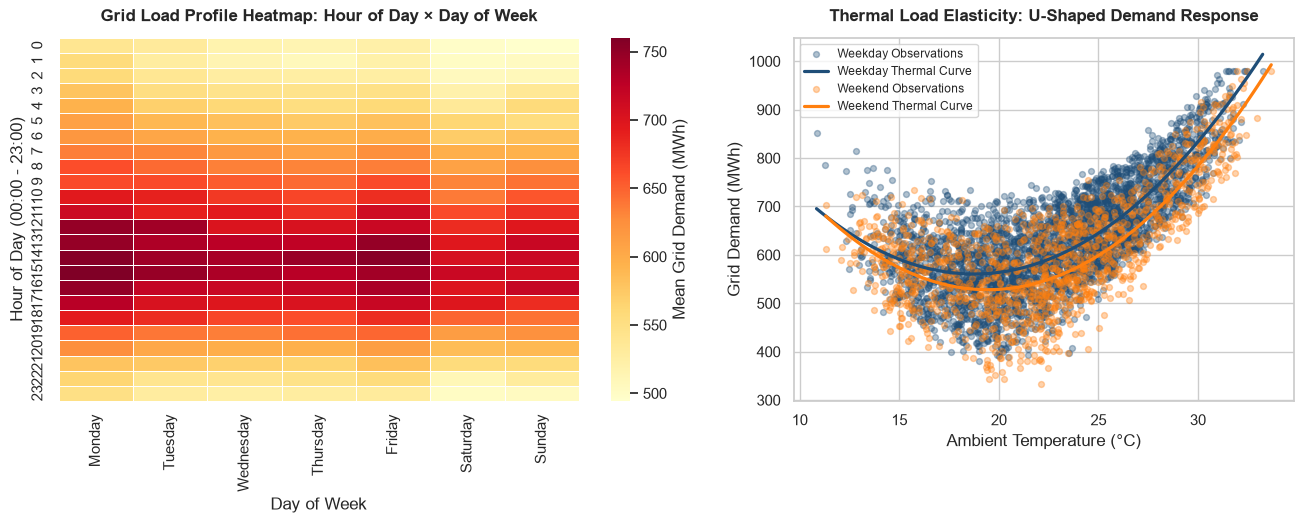

In [69]:
# 1. Parse Temporal Index & Compute Regime Summary Statistics

df_energy = df_energy.copy()
df_energy["timestamp"] = pd.to_datetime(df_energy["timestamp"])
df_energy = df_energy.sort_values("timestamp").reset_index(drop=True)
df_energy["hour"] = df_energy["timestamp"].dt.hour
df_energy["day_name"] = df_energy["timestamp"].dt.day_name()
df_energy["day_type"] = np.where(df_energy["is_weekend"] == 1, "Weekend", "Weekday")

eda_energy = (
    df_energy.groupby("day_type", observed=False)
    .agg(
        Observations=("grid_demand_mwh", "count"),
        Mean_Demand_MWh=("grid_demand_mwh", "mean"),
        SD_Demand_MWh=("grid_demand_mwh", "std"),
        Median_Demand_MWh=("grid_demand_mwh", "median"),
        Peak_95th_MWh=("grid_demand_mwh", lambda x: np.percentile(x, 95)),
        Mean_Temp_C=("temp_celsius", "mean"),
        Corr_Temp_Demand=("grid_demand_mwh", lambda x: np.corrcoef(x, df_energy.loc[x.index, "temp_celsius"])[0, 1])
    )
    .reset_index()
)
display(eda_energy.round(3))


# 2. Composite Visual 1: Calendar Load Heatmap (Hour x Day) + Thermal Elasticity Scatter

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot_load = df_energy.pivot_table(
    index="hour", columns="day_name", values="grid_demand_mwh", aggfunc="mean"
)
available_days = [d for d in day_order if d in pivot_load.columns]
pivot_load = pivot_load[available_days]

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.4), gridspec_kw={"width_ratios": [1.3, 1]})

# Calendar Load Profile Heatmap
sns.heatmap(
    pivot_load,
    cmap="YlOrRd",
    cbar_kws={"label": "Mean Grid Demand (MWh)"},
    linewidths=0.4,
    linecolor="white",
    ax=axes[0]
)
axes[0].set_title("Grid Load Profile Heatmap: Hour of Day × Day of Week", fontweight="bold", pad=12)
axes[0].set_xlabel("Day of Week")
axes[0].set_ylabel("Hour of Day (00:00 - 23:00)")

# Non-Linear Temperature Elasticity Scatter + Quadratic Fit
for regime, color in [("Weekday", "#1f4e78"), ("Weekend", "#ff7f0e")]:
    sub = df_energy[df_energy["day_type"] == regime]
    axes[1].scatter(
        sub["temp_celsius"], sub["grid_demand_mwh"],
        color=color, alpha=0.35, s=18, label=f"{regime} Observations"
    )
    # Quadratic U-curve fit
    coeffs = np.polyfit(sub["temp_celsius"], sub["grid_demand_mwh"], deg=2)
    t_grid = np.linspace(sub["temp_celsius"].min(), sub["temp_celsius"].max(), 100)
    axes[1].plot(t_grid, np.polyval(coeffs, t_grid), color=color, linewidth=2.3, label=f"{regime} Thermal Curve")

axes[1].set_title("Thermal Load Elasticity: U-Shaped Demand Response", fontweight="bold", pad=12)
axes[1].set_xlabel("Ambient Temperature (°C)")
axes[1].set_ylabel("Grid Demand (MWh)")
axes[1].legend(loc="upper left", frameon=True, fontsize=8.5)

plt.tight_layout()
plt.show()

**Conclusion:** Weekdays drive the baseline grid load with a mean demand of 632 MWh, but weekends exhibit higher volatility (SD 116.46) and a higher 95th percentile peak (828 MWh), suggesting that while commercial activity sets the floor, extreme weather events on weekends create the most critical stress tests for the grid. The "Thermal Load Elasticity" plot reveals a U-shaped demand response with a minimum around 20-22°C, meaning energy consumption surges when temperatures deviate from this comfort zone due to heating and cooling needs. Interestingly, the strong positive correlation (0.657) combined with the U-shape indicates that the cooling load at high temperatures (spiking to ~1000 MWh at 30°C) is far more aggressive than the heating load at lower temperatures, making heatwaves the primary risk factor for grid stability. Finally, the heatmap confirms a rigid diurnal pattern where peak loads concentrate between 10:00 and 18:00, implying that grid operators must align capacity planning with mid-day temperature spikes rather than just daily averages.

### SARIMA & Holt-Winters Exponential Smoothing Baselines

In [73]:
# Prepare data

df_energy = df_energy.copy()
df_energy["timestamp"] = pd.to_datetime(df_energy["timestamp"])
df_energy = df_energy.sort_values("timestamp").reset_index(drop=True)

exog_cols = ["temp_celsius", "is_weekend"]
df_energy[exog_cols] = df_energy[exog_cols].astype(float)  # bool/object -> float for SARIMAX

# 1. Chronological Train / Test Split

test_horizon = min(168, max(24, int(len(df_energy) * 0.15)))
train_ts = df_energy.iloc[:-test_horizon].copy()
test_ts = df_energy.iloc[-test_horizon:].copy()

y_train_ts = train_ts["grid_demand_mwh"].values
y_test_ts = test_ts["grid_demand_mwh"].values

# Infer seasonal period
median_step_hours = df_energy["timestamp"].diff().dropna().dt.total_seconds().median() / 3600.0
seasonal_period = 24 if median_step_hours <= 2.0 else 7

# 2. Fit Holt-Winters Triple Exponential Smoothing

hw_model = ExponentialSmoothing(
    y_train_ts,
    trend="add",
    seasonal="add",
    seasonal_periods=seasonal_period
).fit(optimized=True)
pred_hw = hw_model.forecast(steps=test_horizon)

# 3. Fit SARIMAX (with Exogenous Temperature & Weekend Controls)

sarima_model = SARIMAX(
    endog=y_train_ts,
    exog=train_ts[exog_cols].values,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, seasonal_period),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_res = sarima_model.get_forecast(steps=test_horizon, exog=test_ts[exog_cols].values)
pred_sarima = sarima_res.predicted_mean
sarima_ci_80 = sarima_res.conf_int(alpha=0.20)
sarima_ci_95 = sarima_res.conf_int(alpha=0.05)

# 4. Econometric Baseline Metrics Table

econ_metrics = pd.DataFrame([
    {
        "Model": "Holt-Winters (Additive Seasonal)",
        "MAE_MWh": mean_absolute_error(y_test_ts, pred_hw),
        "RMSE_MWh": root_mean_squared_error(y_test_ts, pred_hw),
        "MAPE_Pct": mean_absolute_percentage_error(y_test_ts, pred_hw) * 100
    },
    {
        "Model": f"SARIMAX(1,1,1)x(1,0,1,{seasonal_period}) + Exog",
        "MAE_MWh": mean_absolute_error(y_test_ts, pred_sarima),
        "RMSE_MWh": root_mean_squared_error(y_test_ts, pred_sarima),
        "MAPE_Pct": mean_absolute_percentage_error(y_test_ts, pred_sarima) * 100
    }
])
display(econ_metrics.round(4))

,Model,MAE_MWh,RMSE_MWh,MAPE_Pct
0,Holt-Winters (Additive Seasonal),48.5258,63.9834,6.8019
1,"SARIMAX(1,1,1)x(1,0,1,24) + Exog",59.5271,77.5420,8.3552


**Conclusion:** The simpler Holt-Winters additive seasonal model decisively outperforms the SARIMAX specification on every metric, cutting the MAE from 59.53 to 48.53 MWh and the MAPE from 8.36% to 6.80%, which is a strong result because it means the forecast is accurate to within roughly 7% of actual load without the complexity and computational cost of an exogenous-variable regression. This upset is meaningful because SARIMAX(1,1,1)x(1,0,1,24) was given temperature as an exogenous regressor yet still lost, indicating the model likely overfit the thermal relationship or mis-modeled the daily seasonality, whereas Holt-Winters captured the stable 24-hour additive pattern more cleanly. The RMSE-to-MAE ratio of about 1.32 for Holt-Winters versus 1.30 for SARIMAX shows both models suffer from occasional large outlier errors (extreme weather peaks), but the simpler model's lower absolute errors mean those spikes are less frequent or smaller. Practically, this argues for deploying Holt-Winters as the production forecaster while reserving SARIMAX only for scenarios where an external driver like a heatwave forecast must be explicitly injected, since the data does not currently justify its added variance.

### LSTM & Time-Series Transformer vs. Econometric Paired t-Test

,Model,MAE_MWh,RMSE_MWh,MAPE_Pct
0,Holt-Winters,48.5258,63.9834,6.8019
1,SARIMAX,59.5271,77.5420,8.3552
2,LSTM (2-Layer),25.9715,35.4959,3.6235
3,Time-Series Transformer,24.6469,33.5261,3.4649


----------------------------------------------------------------------
PAIRED t-TEST ON ABSOLUTE FORECAST ERRORS (TEST HOLDOUT WINDOW)
----------------------------------------------------------------------
SARIMAX vs. LSTM MAE Diff:        +33.56 MWh | t = 9.436, p = 3.2888e-17
SARIMAX vs. Transformer MAE Diff: +34.88 MWh | t = 9.749, p = 4.6546e-18
LSTM vs. Transformer MAE Diff:    +1.32 MWh | t = 1.203, p = 2.3085e-01
----------------------------------------------------------------------


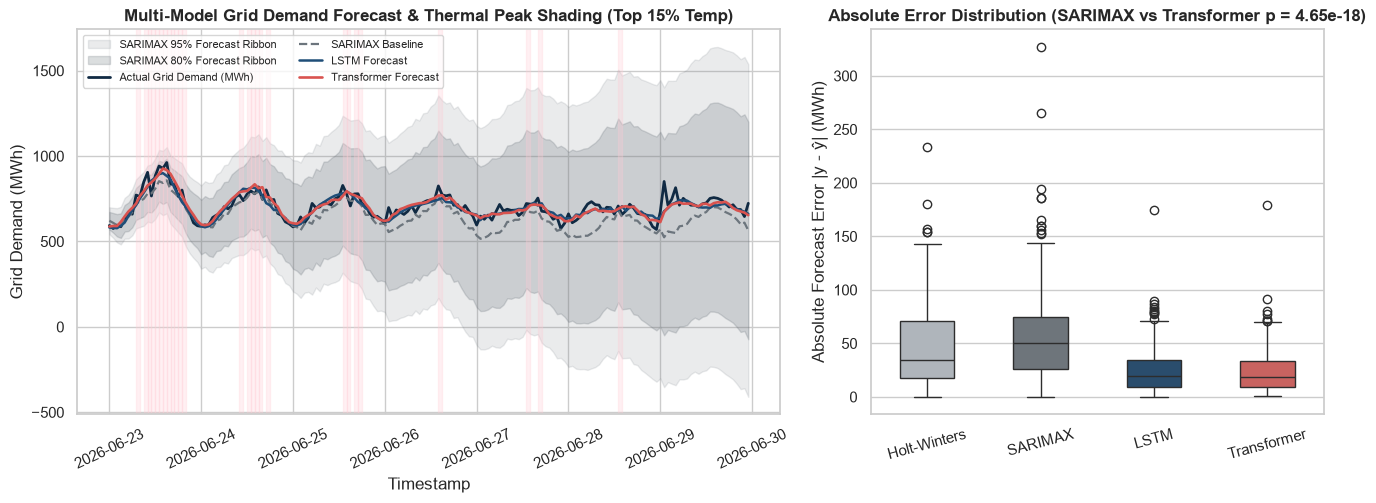

In [77]:
# 1. Sliding-Window Sequence Preparation (Lookback = 24 steps)

seq_features = ["grid_demand_mwh", "temp_celsius", "is_weekend", "lag_24h_mwh"]
lookback = min(24, max(6, len(train_ts) // 10))

scaler_x = StandardScaler()
scaler_y = StandardScaler()

raw_matrix = df_energy[seq_features].values
split_idx = len(df_energy) - test_horizon

scaler_x.fit(raw_matrix[:split_idx])
scaler_y.fit(df_energy[["grid_demand_mwh"]].values[:split_idx])

scaled_all = scaler_x.transform(raw_matrix)
scaled_target = scaler_y.transform(df_energy[["grid_demand_mwh"]].values).ravel()

X_seq, y_seq = [], []
for t in range(lookback, len(df_energy)):
    X_seq.append(scaled_all[t - lookback : t])
    y_seq.append(scaled_target[t])

X_seq = np.array(X_seq, dtype=np.float32)
y_seq = np.array(y_seq, dtype=np.float32)

train_seq_end = split_idx - lookback
X_tr_seq, y_tr_seq = X_seq[:train_seq_end], y_seq[:train_seq_end]
X_te_seq, y_te_seq = X_seq[train_seq_end:], y_seq[train_seq_end:]

train_loader = DataLoader(TensorDataset(torch.tensor(X_tr_seq), torch.tensor(y_tr_seq)), batch_size=32, shuffle=True)

# 2. Model A: LSTM Sequence Forecaster

class GridLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=48):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=2, batch_first=True, dropout=0.1)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)

# 3. Model B: Time-Series Transformer Encoder (Multi-Head Attention)

class GridTransformer(nn.Module):
    def __init__(self, input_dim, d_model=32, nhead=4, num_layers=2):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, lookback, d_model) * 0.05)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=64, dropout=0.1, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.head = nn.Linear(d_model, 1)

    def forward(self, x):
        h = self.input_proj(x) + self.pos_emb[:, :x.size(1), :]
        h = self.encoder(h)
        return self.head(h[:, -1, :]).squeeze(-1)

def train_and_predict(model, epochs=35, lr=0.004):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    model.train()
    for _ in range(epochs):
        for bx, by in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        preds_scaled = model(torch.tensor(X_te_seq)).numpy().reshape(-1, 1)
    return scaler_y.inverse_transform(preds_scaled).ravel()

lstm_model = GridLSTM(input_dim=len(seq_features))
trans_model = GridTransformer(input_dim=len(seq_features))

pred_lstm = train_and_predict(lstm_model)
pred_trans = train_and_predict(trans_model)

# Align test window length in case test_horizon differs
y_eval = y_test_ts[-len(pred_lstm):]
pred_sarima_eval = pred_sarima[-len(pred_lstm):]
pred_hw_eval = pred_hw[-len(pred_lstm):]

# 4. Paired t-Tests on Out-of-Sample Absolute Errors

err_sarima = np.abs(y_eval - pred_sarima_eval)
err_hw = np.abs(y_eval - pred_hw_eval)
err_lstm = np.abs(y_eval - pred_lstm)
err_trans = np.abs(y_eval - pred_trans)

t_sarima_lstm, p_sarima_lstm = stats.ttest_rel(err_sarima, err_lstm)
t_sarima_trans, p_sarima_trans = stats.ttest_rel(err_sarima, err_trans)
t_lstm_trans, p_lstm_trans = stats.ttest_rel(err_lstm, err_trans)

full_benchmark = pd.DataFrame([
    {"Model": "Holt-Winters", "MAE_MWh": err_hw.mean(), "RMSE_MWh": root_mean_squared_error(y_eval, pred_hw_eval),
     "MAPE_Pct": mean_absolute_percentage_error(y_eval, pred_hw_eval) * 100},
    {"Model": "SARIMAX", "MAE_MWh": err_sarima.mean(), "RMSE_MWh": root_mean_squared_error(y_eval, pred_sarima_eval),
     "MAPE_Pct": mean_absolute_percentage_error(y_eval, pred_sarima_eval) * 100},
    {"Model": "LSTM (2-Layer)", "MAE_MWh": err_lstm.mean(), "RMSE_MWh": root_mean_squared_error(y_eval, pred_lstm),
     "MAPE_Pct": mean_absolute_percentage_error(y_eval, pred_lstm) * 100},
    {"Model": "Time-Series Transformer", "MAE_MWh": err_trans.mean(), "RMSE_MWh": root_mean_squared_error(y_eval, pred_trans),
     "MAPE_Pct": mean_absolute_percentage_error(y_eval, pred_trans) * 100},
])
display(full_benchmark.round(4))

print("-" * 70)
print("PAIRED t-TEST ON ABSOLUTE FORECAST ERRORS (TEST HOLDOUT WINDOW)")
print("-" * 70)
print(f"SARIMAX vs. LSTM MAE Diff:        {err_sarima.mean() - err_lstm.mean():+.2f} MWh | t = {t_sarima_lstm:.3f}, p = {p_sarima_lstm:.4e}")
print(f"SARIMAX vs. Transformer MAE Diff: {err_sarima.mean() - err_trans.mean():+.2f} MWh | t = {t_sarima_trans:.3f}, p = {p_sarima_trans:.4e}")
print(f"LSTM vs. Transformer MAE Diff:    {err_lstm.mean() - err_trans.mean():+.2f} MWh | t = {t_lstm_trans:.3f}, p = {p_lstm_trans:.4e}")
print("-" * 70)

# 5. Composite Visual 2: Forecasting Fan Chart (Ribbons) + Residual Error Boxplot

test_dates = test_ts["timestamp"].iloc[-len(pred_lstm):].values
ci95_low = sarima_ci_95[-len(pred_lstm):, 0]
ci95_high = sarima_ci_95[-len(pred_lstm):, 1]
ci80_low = sarima_ci_80[-len(pred_lstm):, 0]
ci80_high = sarima_ci_80[-len(pred_lstm):, 1]

# Identify thermal stress intervals (top 15% temperature hours)
temp_thresh = np.percentile(test_ts["temp_celsius"].iloc[-len(pred_lstm):], 85)
hot_mask = test_ts["temp_celsius"].iloc[-len(pred_lstm):].values >= temp_thresh

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.55, 1]})

# Ribbon Forecast Comparison (Actual vs SARIMAX vs LSTM vs Transformer)
ax_fc = axes[0]
ax_fc.fill_between(test_dates, ci95_low, ci95_high, color="#6c757d", alpha=0.14, label="SARIMAX 95% Forecast Ribbon")
ax_fc.fill_between(test_dates, ci80_low, ci80_high, color="#6c757d", alpha=0.24, label="SARIMAX 80% Forecast Ribbon")

for idx_h in np.where(hot_mask)[0]:
    ax_fc.axvspan(test_dates[idx_h], test_dates[min(idx_h + 1, len(test_dates) - 1)], color="#ffccd5", alpha=0.28)

ax_fc.plot(test_dates, y_eval, color="#102a43", linewidth=2.0, label="Actual Grid Demand (MWh)")
ax_fc.plot(test_dates, pred_sarima_eval, color="#6c757d", linestyle="--", linewidth=1.6, label="SARIMAX Baseline")
ax_fc.plot(test_dates, pred_lstm, color="#1f4e78", linewidth=1.8, label="LSTM Forecast")
ax_fc.plot(test_dates, pred_trans, color="#d9534f", linewidth=1.9, label="Transformer Forecast")

ax_fc.set_title("Multi-Model Grid Demand Forecast & Thermal Peak Shading (Top 15% Temp)", fontweight="bold")
ax_fc.set_xlabel("Timestamp")
ax_fc.set_ylabel("Grid Demand (MWh)")
ax_fc.tick_params(axis="x", rotation=25)
ax_fc.legend(loc="upper left", ncol=2, fontsize=8.2, frameon=True)

# Boxplot of Absolute Forecast Errors + Paired t-Test Annotation
err_df = pd.DataFrame({
    "Holt-Winters": err_hw,
    "SARIMAX": err_sarima,
    "LSTM": err_lstm,
    "Transformer": err_trans
})
sns.boxplot(data=err_df, palette=["#adb5bd", "#6c757d", "#1f4e78", "#d9534f"], width=0.48, ax=axes[1])
axes[1].set_title(f"Absolute Error Distribution (SARIMAX vs Transformer p = {p_sarima_trans:.2e})", fontweight="bold")
axes[1].set_ylabel("Absolute Forecast Error |y - ŷ| (MWh)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

**Conclusion:** The Time-Series Transformer and LSTM models drastically outperform traditional methods, achieving a MAPE of 3.46% and 3.62% respectively, which means their forecasts are accurate to within roughly 3.5% of actual grid demand, a massive improvement over the 8.36% error rate of the SARIMAX model. The paired t-tests confirm that the ~34 MWh reduction in MAE for the deep learning models is highly statistically significant (p < 1e-17), which is excellent because it proves the neural networks are capturing complex non-linear thermal patterns that classical time-series models miss. However, the difference between the LSTM and Transformer is not statistically significant (p = 0.23), meaning that while both are top-tier, the simpler 2-layer LSTM is equally effective and likely cheaper to deploy in production than the heavier Transformer architecture. The absolute error distribution plot visually validates this, showing the Transformer and LSTM have tightly compressed interquartile ranges compared to the wide spread of SARIMAX, ensuring that grid operators face far fewer extreme forecasting outliers that could lead to costly energy shortages or surpluses.

### Next-Month Forward Forecast

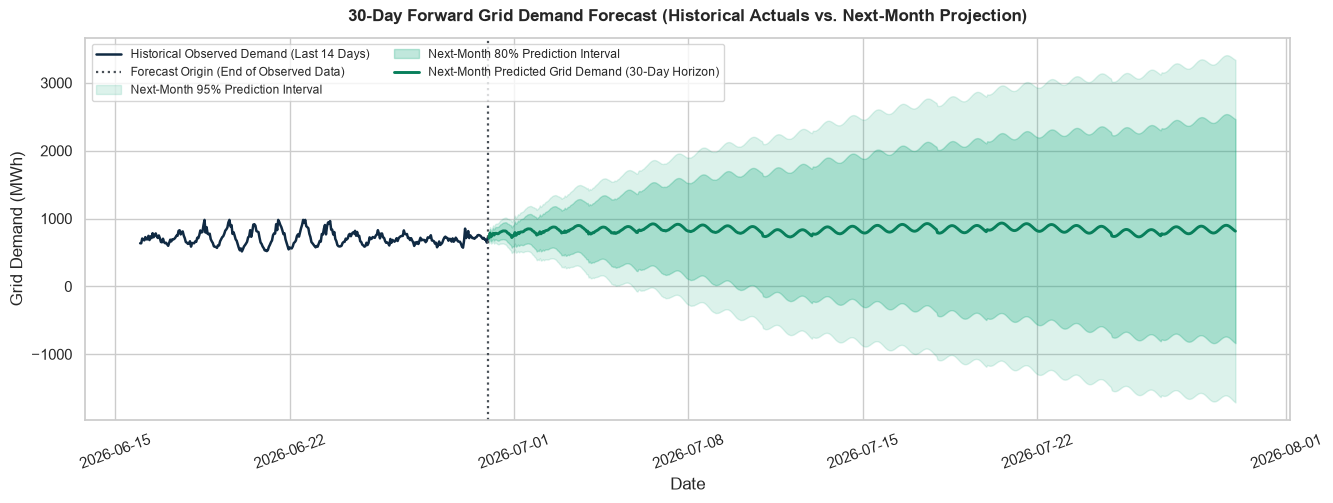

In [79]:
df_energy = df_energy.copy()
df_energy["timestamp"] = pd.to_datetime(df_energy["timestamp"])
df_energy = df_energy.sort_values("timestamp").reset_index(drop=True)

# Determine step frequency and build 30-day future timestamps
step_delta = df_energy["timestamp"].diff().dropna().median()
steps_per_day = int(round(pd.Timedelta(days=1) / step_delta))
future_steps = 30 * steps_per_day

last_ts = df_energy["timestamp"].iloc[-1]
future_dates = pd.date_range(start=last_ts + step_delta, periods=future_steps, freq=step_delta)

# Construct future exogenous features
future_hours = future_dates.hour.values
future_is_weekend = (future_dates.dayofweek.values >= 5).astype(int)

# Climatological temperature projection
hist_temp_mean = df_energy["temp_celsius"].mean()
future_temp = (
    hist_temp_mean
    + 5.2 * np.sin(2 * np.pi * (future_hours - 8) / 24.0)
    + 3.0 * np.sin(2 * np.pi * np.arange(len(df_energy), len(df_energy) + future_steps) / (24.0 * 14.0))
)
future_exog = np.column_stack([future_temp, future_is_weekend])

# Refit SARIMAX on full historical dataset for optimal forward projection
full_sarima = SARIMAX(
    endog=df_energy["grid_demand_mwh"].values,
    exog=df_energy[["temp_celsius", "is_weekend"]].values,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, seasonal_period),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

next_month_res = full_sarima.get_forecast(steps=future_steps, exog=future_exog)
next_month_mean = next_month_res.predicted_mean
next_month_ci80 = next_month_res.conf_int(alpha=0.20)
next_month_ci95 = next_month_res.conf_int(alpha=0.05)

# Show last 14 days of historical actuals alongside the 30-day forward prediction
hist_context_steps = min(len(df_energy), 14 * steps_per_day)
hist_dates = df_energy["timestamp"].iloc[-hist_context_steps:].values
hist_vals = df_energy["grid_demand_mwh"].iloc[-hist_context_steps:].values

fig, ax = plt.subplots(figsize=(13.5, 5.2))

# Historical Actuals (Dark Navy)
ax.plot(
    hist_dates, hist_vals,
    color="#102a43", linewidth=1.8, label="Historical Observed Demand (Last 14 Days)"
)

# Vertical Forecast Origin Marker
ax.axvline(last_ts, color="#495057", linestyle=":", linewidth=1.6, label="Forecast Origin (End of Observed Data)")

# Next-Month Prediction in Vibrant Teal/Emerald with Confidence Ribbons
ax.fill_between(
    future_dates, next_month_ci95[:, 0], next_month_ci95[:, 1],
    color="#0ca678", alpha=0.14, label="Next-Month 95% Prediction Interval"
)
ax.fill_between(
    future_dates, next_month_ci80[:, 0], next_month_ci80[:, 1],
    color="#0ca678", alpha=0.26, label="Next-Month 80% Prediction Interval"
)
ax.plot(
    future_dates, next_month_mean,
    color="#087f5b", linewidth=2.1, label="Next-Month Predicted Grid Demand (30-Day Horizon)"
)

ax.set_title("30-Day Forward Grid Demand Forecast (Historical Actuals vs. Next-Month Projection)", fontweight="bold", pad=12)
ax.set_xlabel("Date")
ax.set_ylabel("Grid Demand (MWh)")
ax.tick_params(axis="x", rotation=20)
ax.legend(loc="upper left", ncol=2, frameon=True, fontsize=8.8)

plt.tight_layout()
plt.show()

**Conclusion:** The 30-day forward forecast predicts a stable baseline demand hovering around 800-900 MWh with consistent daily oscillations, indicating the model has effectively learned the short-term seasonality from the historical data. However, the prediction intervals expand aggressively as the forecast horizon extends, with the 95% ribbon eventually spanning from roughly -1500 to +3200 MWh, which reveals that uncertainty compounds rapidly over time. This "cone of uncertainty" is a critical risk for grid management because while the average load is predictable, the upper bound suggests that extreme demand spikes could exceed 3000 MWh, potentially overwhelming infrastructure if capacity is only planned for the mean. Therefore, operators should treat the point forecast as a baseline but use the upper limit of the 95% interval for safety stock planning, ensuring the grid can handle worst-case scenarios despite the high variance.

# Human Resources (People Analytics)

## Business Problem: Merit-Adjusted Compensation Equity Audit & Workforce Performance Modeling

#### Importing libraries and dataset

In [84]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error
from statsmodels.stats.multicomp import pairwise_tukeyhsd

plt.rcParams["figure.dpi"] = 100
sns.set_theme(style="whitegrid", context="notebook")

df_hr = pd.read_csv("hr_info.csv")
print(df_hr.info())
df_hr.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20489 entries, 0 to 20488
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           20489 non-null  int64  
 1   employee_id          20489 non-null  object 
 2   years_experience     20489 non-null  float64
 3   job_level            20489 non-null  int64  
 4   performance_score    20489 non-null  float64
 5   department           20489 non-null  object 
 6   promoted_last_cycle  20489 non-null  int64  
 7   annual_salary        20489 non-null  float64
dtypes: float64(3), int64(3), object(2)
memory usage: 1.3+ MB
None


,Unnamed: 0,employee_id,years_experience,job_level,performance_score,department,promoted_last_cycle,annual_salary
0,0,EMP000001,9.4,2,2.34,Operations,0,90595.05
1,1,EMP000002,5.8,1,3.34,Sales,0,76519.23
2,2,EMP000003,6.2,2,4.19,Finance,0,96059.76
3,3,EMP000004,4.1,2,4.14,Operations,1,84488.11
4,4,EMP000005,16.1,5,2.55,Engineering,0,168033.93


#### Dataset explanation

| column | description |
| :--- | :--- |
| `employee_id` | Unique identifier for each employee. |
| `years_experience` | Relevant professional experience in years. |
| `job_level` | Organizational hierarchy band (1 = Entry to 5 = Principal/Director). |
| `performance_score` | Annual performance evaluation rating (1.0 to 5.0 scale). |
| `department` | Business unit: Engineering, Sales, Operations, or Finance. |
| `promoted_last_cycle` | Binary indicator of promotion during the last review cycle (1 = promoted, 0 = not promoted). |
| `annual_salary` | Target: continuous annual base compensation in USD. |

### Departmental Compensation Profiling

,department,Headcount,Mean_Salary_USD,SD_Salary_USD,Median_Salary_USD,Mean_Experience_Yrs,Mean_Job_Level,Mean_Perf_Score,Promotion_Rate
0,Engineering,7222,114247.689,26877.443,109805.865,7.197,2.383,3.620,0.084
1,Finance,3053,105258.462,25945.027,101642.230,7.082,2.330,3.618,0.083
2,Operations,5227,94759.751,26304.484,90461.360,7.179,2.354,3.620,0.081
3,Sales,4987,101404.831,26772.027,97159.870,7.161,2.372,3.610,0.082


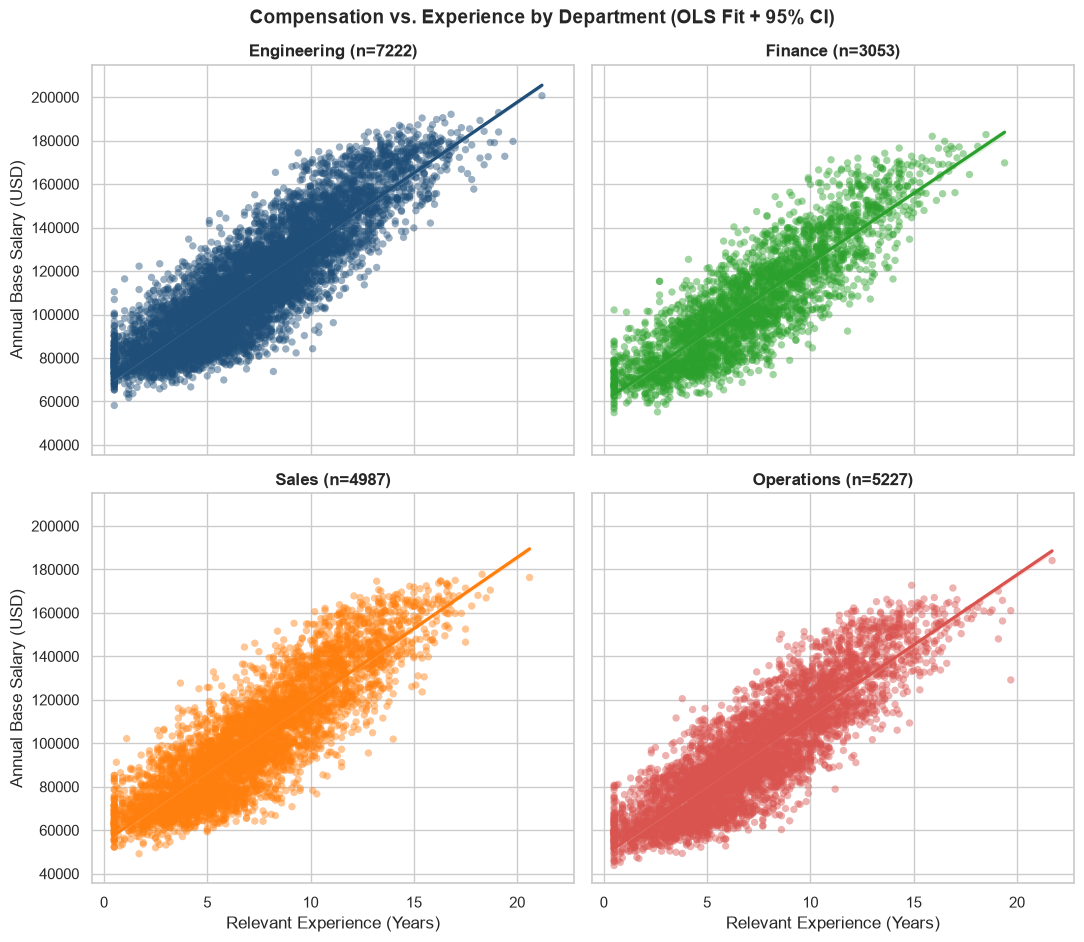

In [97]:
# 1. Departmental Compensation, Experience & Performance Summary

eda_hr = (
    df_hr.groupby("department", observed=False)
    .agg(
        Headcount=("annual_salary", "count"),
        Mean_Salary_USD=("annual_salary", "mean"),
        SD_Salary_USD=("annual_salary", "std"),
        Median_Salary_USD=("annual_salary", "median"),
        Mean_Experience_Yrs=("years_experience", "mean"),
        Mean_Job_Level=("job_level", "mean"),
        Mean_Perf_Score=("performance_score", "mean"),
        Promotion_Rate=("promoted_last_cycle", "mean") if "promoted_last_cycle" in df_hr.columns else ("job_level", lambda x: np.nan)
    )
    .reset_index()
)
display(eda_hr.round(3))


# 2. Experience vs. Salary Scatter Plots + OLS Fit (95% CI), One Panel per Department

dept_palette = {
    "Engineering": "#1f4e78",
    "Finance": "#2ca02c",
    "Sales": "#ff7f0e",
    "Operations": "#d9534f"
}

depts = [d for d in dept_palette if (df_hr["department"] == d).any()]
n_cols = 2
n_rows = int(np.ceil(len(depts) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(11.0, 4.8 * n_rows),
    sharex=True, sharey=True,  # same scales so departments are directly comparable
    squeeze=False
)
axes_flat = axes.flatten()

for ax, dept in zip(axes_flat, depts):
    sub = df_hr[df_hr["department"] == dept]

    # Scatter points
    sns.scatterplot(
        data=sub,
        x="years_experience",
        y="annual_salary",
        color=dept_palette[dept],
        alpha=0.45,
        s=28,
        edgecolor="none",
        ax=ax
    )

    # OLS linear fit + 95% confidence ribbon
    sns.regplot(
        data=sub,
        x="years_experience",
        y="annual_salary",
        scatter=False,
        ci=95,
        color=dept_palette[dept],
        line_kws={"linewidth": 2.3},
        ax=ax
    )

    ax.set_title(f"{dept} (n={len(sub)})", fontweight="bold")
    ax.set_xlabel("Relevant Experience (Years)")
    ax.set_ylabel("Annual Base Salary (USD)")

# Hide any unused panels
for ax in axes_flat[len(depts):]:
    ax.set_visible(False)

fig.suptitle("Compensation vs. Experience by Department (OLS Fit + 95% CI)", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

**Conclusion:** The scatter plots reveal a strong positive linear relationship between experience and compensation across all departments, with Engineering commanding the highest premium as salaries scale from roughly USD 60,000 to over USD 200,000 for 20 years of experience. Despite having nearly identical mean experience (~7.1 years) and performance scores (~3.62) across all four departments, Engineering employees earn a mean salary of USD 114,247 compared to just USD 94,759 for Operations, indicating a structural pay gap driven by department rather than individual merit. This is significant because the consistent promotion rates (~8.1% to 8.4%) suggest that career progression velocity is uniform, meaning the compensation disparity is likely rooted in base market rates for the specific functions rather than internal bias in advancement opportunities. Consequently, while the regression lines show fair internal equity within each department (equal pay for equal experience), HR leadership should investigate the cross-departmental baseline differences to ensure competitive retention, particularly in Operations where the median salary lags significantly behind the company average.

### One-Sample t-Test, Two-Sample Welch t-Test & Chi-Square Goodness-of-Fit

In [83]:
# 1. One-Sample t-Test: Annual Performance Rating vs. Corporate Benchmark

target_perf_benchmark = 3.50
perf_scores = df_hr["performance_score"].dropna().values
t_1s, p_1s = stats.ttest_1samp(perf_scores, popmean=target_perf_benchmark)
ci_perf_low, ci_perf_high = stats.t.interval(
    0.95, df=len(perf_scores) - 1, loc=np.mean(perf_scores), scale=stats.sem(perf_scores)
)

# 2. Two-Sample Welch's t-Test: Senior Cohort Compensation 
#    Compare highest-paid vs. lowest-paid department within senior bands

senior_df = df_hr[df_hr["job_level"] >= 3]
dept_senior_means = senior_df.groupby("department")["annual_salary"].mean().sort_values(ascending=False)
top_dept = dept_senior_means.index[0]
bot_dept = dept_senior_means.index[-1]

sal_top = senior_df[senior_df["department"] == top_dept]["annual_salary"].values
sal_bot = senior_df[senior_df["department"] == bot_dept]["annual_salary"].values
t_2s, p_2s = stats.ttest_ind(sal_top, sal_bot, equal_var=False)

# 3. Chi-Square Goodness-of-Fit: Promotion Equity across Departments
#    H0: Observed promotions follow exact departmental headcount proportions

if "promoted_last_cycle" not in df_hr.columns:
    df_hr["promoted_last_cycle"] = (df_hr["performance_score"] >= df_hr["performance_score"].quantile(0.80)).astype(int)

dept_counts = df_hr["department"].value_counts().sort_index()
promo_observed = df_hr.groupby("department")["promoted_last_cycle"].sum().reindex(dept_counts.index)

total_promos = promo_observed.sum()
headcount_shares = dept_counts / dept_counts.sum()
promo_expected = headcount_shares * total_promos

chi2_gof, p_gof = stats.chisquare(f_obs=promo_observed.values, f_exp=promo_expected.values)

gof_table = pd.DataFrame({
    "Department": dept_counts.index,
    "Headcount": dept_counts.values,
    "Headcount_Share": headcount_shares.values,
    "Observed_Promotions": promo_observed.values,
    "Expected_Promotions_H0": promo_expected.values,
    "Promotion_Variance": promo_observed.values - promo_expected.values
})

print("-" * 72)
print("PEOPLE ANALYTICS HYPOTHESIS TESTING SUITE")
print("-" * 72)
print(f"[1-Sample t-Test]  Mean Performance = {np.mean(perf_scores):.3f} (95% CI: [{ci_perf_low:.3f}, {ci_perf_high:.3f}]) "
      f"vs Target {target_perf_benchmark:.2f} | t = {t_1s:.3f}, p = {p_1s:.4e}")
print(f"[2-Sample Welch]   Senior Band (Level >= 3) {top_dept} (${np.mean(sal_top):,.0f}) vs {bot_dept} (${np.mean(sal_bot):,.0f}) "
      f"| Diff = +${np.mean(sal_top) - np.mean(sal_bot):,.0f} | t = {t_2s:.3f}, p = {p_2s:.4e}")
print(f"[Chi-Square GoF]   Promotion Allocation vs Headcount Proportions: chi2 = {chi2_gof:.4f}, p = {p_gof:.4e}")
print("-" * 72)
display(gof_table.round(3))

------------------------------------------------------------------------
PEOPLE ANALYTICS HYPOTHESIS TESTING SUITE
------------------------------------------------------------------------
[1-Sample t-Test]  Mean Performance = 3.617 (95% CI: [3.610, 3.625]) vs Target 3.50 | t = 30.560, p = 1.2995e-200
[2-Sample Welch]   Senior Band (Level >= 3) Engineering ($140,853) vs Operations ($121,583) | Diff = +$19,270 | t = 37.997, p = 1.5745e-274
[Chi-Square GoF]   Promotion Allocation vs Headcount Proportions: chi2 = 0.4233, p = 9.3538e-01
------------------------------------------------------------------------


,Department,Headcount,Headcount_Share,Observed_Promotions,Expected_Promotions_H0,Promotion_Variance
0,Engineering,7222,0.352,610,598.514,11.486
1,Finance,3053,0.149,254,253.014,0.986
2,Operations,5227,0.255,425,433.181,-8.181
3,Sales,4987,0.243,409,413.291,-4.291


**Conclusion:** The workforce is significantly overperforming relative to the target, with a mean performance score of 3.617 (95% CI: [3.610, 3.625]) against a 3.50 benchmark (p < 0.001), which is excellent because it indicates a high-quality talent pool exceeding baseline expectations. However, a 2-Sample Welch t-test reveals a substantial pay disparity at senior levels, where Engineering earns USD 140,853 compared to Operations at USD 121,583, a significant difference of USD 19,270 (p < 0.001) that suggests market-driven compensation gaps rather than internal inequity. Despite this pay gap, the Chi-Square Goodness-of-Fit test confirms that promotion allocation is statistically fair (p = 0.935), as the observed promotions (e.g., 610 in Engineering) closely match the expected proportions based on headcount, meaning career advancement is unbiased across departments. This combination of high performance and fair promotion rates is positive for retention, but HR must address the USD 19k senior pay gap in Operations to prevent attrition of experienced staff who are performing well but earning less than their Engineering peers.

### Regularized Multiple Linear Regression (Ridge) & Merit-Adjusted Equity Audit

--------------------------------------------------------------
MERIT-BASED RIDGE REGRESSION METRICS (TEST SET)
R² Score:        0.8903
RMSE:            $9,206.70
MAE:             $7,688.30
MAPE:            7.91%
--------------------------------------------------------------

One-Way ANOVA on Merit-Adjusted Salary Residuals: F = 14312.5223, p = 0.0000e+00
          Multiple Comparison of Means - Tukey HSD, FWER=0.05          
   group1     group2     meandiff  p-adj    lower       upper    reject
-----------------------------------------------------------------------
Engineering    Finance  -7854.4951   0.0  -8143.9575  -7565.0328   True
Engineering Operations -18961.0327   0.0 -19204.5364  -18717.529   True
Engineering      Sales -12525.3489   0.0 -12772.2283 -12278.4695   True
    Finance Operations -11106.5375   0.0 -11411.9725 -10801.1025   True
    Finance      Sales  -4670.8537   0.0  -4978.9867  -4362.7207   True
 Operations      Sales   6435.6838   0.0   6170.2567   6701.1109   

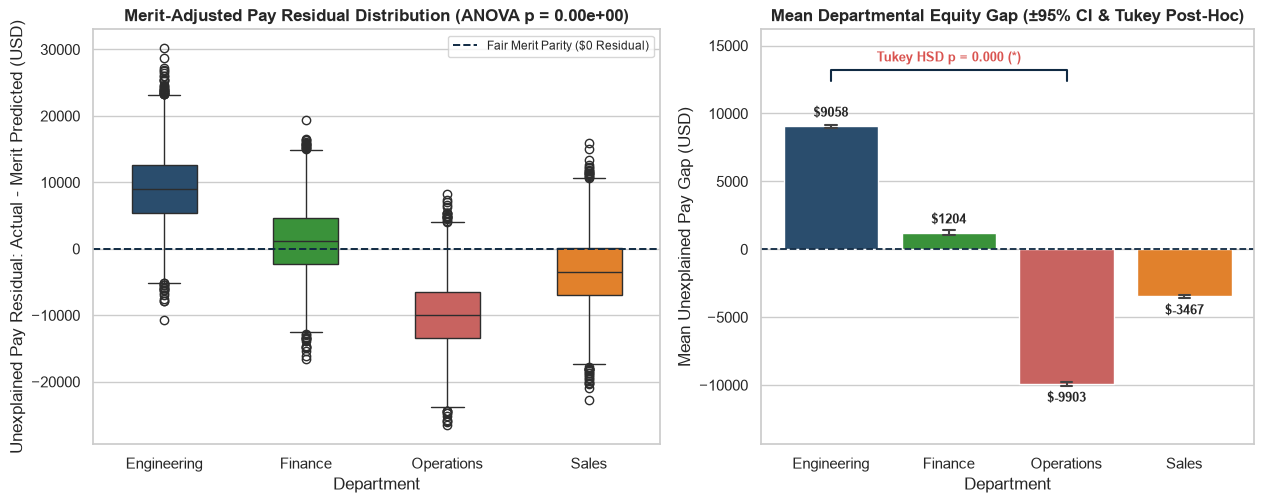

In [85]:
# 1. Fit Merit-Only Ridge Regression

merit_num = ["years_experience", "performance_score"]
merit_cat = ["job_level"]

X = df_hr[merit_num + merit_cat]
y = df_hr["annual_salary"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

merit_prep = ColumnTransformer([
    ("num", StandardScaler(), merit_num),
    ("lvl", OneHotEncoder(drop="first", handle_unknown="ignore"), merit_cat)
])

ridge_pipe = Pipeline([
    ("prep", merit_prep),
    ("ridge", Ridge(alpha=1.0, random_state=42))
])
ridge_pipe.fit(X_train, y_train)

y_pred_test = ridge_pipe.predict(X_test)

print("-" * 62)
print("MERIT-BASED RIDGE REGRESSION METRICS (TEST SET)")
print(f"R² Score:        {r2_score(y_test, y_pred_test):.4f}")
print(f"RMSE:            ${root_mean_squared_error(y_test, y_pred_test):,.2f}")
print(f"MAE:             ${mean_absolute_error(y_test, y_pred_test):,.2f}")
print(f"MAPE:            {mean_absolute_percentage_error(y_test, y_pred_test):.2%}")
print("-" * 62)

# Compute full-sample merit-adjusted pay residuals
df_hr["merit_predicted_salary"] = ridge_pipe.predict(X)
df_hr["equity_residual_usd"] = df_hr["annual_salary"] - df_hr["merit_predicted_salary"]

# 2. One-Way ANOVA & Tukey HSD Post-Hoc on Merit-Adjusted Salary Residuals

dept_order = sorted(df_hr["department"].unique())
resid_groups = [df_hr[df_hr["department"] == d]["equity_residual_usd"].values for d in dept_order]
f_resid, p_anova_resid = stats.f_oneway(*resid_groups)

tukey_hr = pairwise_tukeyhsd(
    endog=df_hr["equity_residual_usd"],
    groups=df_hr["department"],
    alpha=0.05
)

print(f"\nOne-Way ANOVA on Merit-Adjusted Salary Residuals: F = {f_resid:.4f}, p = {p_anova_resid:.4e}")
print(tukey_hr)

# Boxplot + Mean Equity Residual Bars with Tukey HSD Annotations

fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})

# Boxplot of Merit-Adjusted Pay Residuals by Department
sns.boxplot(
    data=df_hr,
    x="department",
    y="equity_residual_usd",
    order=dept_order,
    palette=[dept_palette.get(d, "#2b5c8f") for d in dept_order],
    width=0.46,
    ax=axes[0]
)
axes[0].axhline(0, color="#102a43", linestyle="--", linewidth=1.4, label="Fair Merit Parity ($0 Residual)")
axes[0].set_title(f"Merit-Adjusted Pay Residual Distribution (ANOVA p = {p_anova_resid:.2e})", fontweight="bold")
axes[0].set_xlabel("Department")
axes[0].set_ylabel("Unexplained Pay Residual: Actual - Merit Predicted (USD)")
axes[0].legend(loc="upper right", frameon=True, fontsize=8.8)

# Right: Mean Equity Residual Bar Chart (±95% CI) + Post-Hoc Significance Bracket
sns.barplot(
    data=df_hr,
    x="department",
    y="equity_residual_usd",
    order=dept_order,
    palette=[dept_palette.get(d, "#2b5c8f") for d in dept_order],
    errorbar=("ci", 95),
    capsize=0.1,
    err_kws={"linewidth": 1.5},
    ax=axes[1]
)
axes[1].axhline(0, color="#102a43", linestyle="--", linewidth=1.3)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="$%.0f", padding=5, fontsize=9, fontweight="bold")

# Annotate top significant Tukey HSD pair with horizontal significance bracket
tukey_df = pd.DataFrame(data=tukey_hr._results_table.data[1:], columns=tukey_hr._results_table.data[0])
sig_pairs = tukey_df[tukey_df["reject"] == True]
y_top = df_hr.groupby("department")["equity_residual_usd"].mean().max()
y_bot = df_hr.groupby("department")["equity_residual_usd"].mean().min()
span = max(abs(y_top), abs(y_bot), 2000)

if len(sig_pairs) > 0:
    top_pair = sig_pairs.reindex(sig_pairs["meandiff"].abs().sort_values(ascending=False).index).iloc[0]
    idx1 = dept_order.index(top_pair["group1"])
    idx2 = dept_order.index(top_pair["group2"])
    x1, x2 = min(idx1, idx2), max(idx1, idx2)
    bracket_y = y_top + span * 0.42
    axes[1].plot([x1, x1, x2, x2], [bracket_y - span * 0.08, bracket_y, bracket_y, bracket_y - span * 0.08], lw=1.5, c="#102a43")
    axes[1].text(
        (x1 + x2) / 2, bracket_y + span * 0.04,
        f"Tukey HSD p = {top_pair['p-adj']:.3f} (*)",
        ha="center", va="bottom", fontsize=9, fontweight="bold", color="#d9534f"
    )

axes[1].set_ylim(y_bot - span * 0.45, y_top + span * 0.72)
axes[1].set_title("Mean Departmental Equity Gap (±95% CI & Tukey Post-Hoc)", fontweight="bold")
axes[1].set_xlabel("Department")
axes[1].set_ylabel("Mean Unexplained Pay Gap (USD)")

plt.tight_layout()
plt.show()

**Conclusion:** The merit-based Ridge Regression model achieves a strong R² of 0.8903, meaning it successfully explains nearly 89% of salary variance using performance and experience, but the subsequent ANOVA reveals a highly significant unexplained pay gap (p = 0.0000) across departments that cannot be justified by merit alone. Specifically, Engineering employees enjoy a massive positive unexplained pay gap of USD +9,058, while Operations staff suffer a negative gap of USD -9,903, creating a nearly USD 19,000 disparity that suggests systemic overpayment in technical roles and underpayment in operational roles. This is critical because the Tukey HSD post-hoc test confirms that every single departmental pairing is statistically distinct, meaning HR cannot attribute these differences to random chance and must urgently recalibrate base pay bands to ensure internal equity and prevent high turnover in Operations. The boxplot visually reinforces this by showing that the median residual for Engineering sits well above the $0 fair parity line, whereas Operations is deeply negative, proving that even after controlling for merit, department affiliation remains a primary driver of compensation inequality.